
# FlightAura — Deep Learning and Ensemble Learning

## Objective

Implement and compare deep learning architectures for airline passenger review classification.

## Architectures
1. Artificial Neural Network (ANN)
2. SimpleRNN
3. LSTM
4. GRU
5. Bidirectional LSTM
6. Custom Self-Attention using Query, Key and Value

## Other concepts
- Word2Vec embeddings
- Embedding layers
- Positional encoding
- Adam optimizer
- Weight initialization
- Dropout
- EarlyStopping
- TensorBoard
- Classification evaluation
- Ensemble learning

## Targets
1. Three-class rating-derived sentiment classification.
2. Binary passenger recommendation prediction.

## Dataset
Unique airline passenger reviews from Notebook 02.


In [1]:

# ==========================================
# 1. IMPORT LIBRARIES
# ==========================================

import os
import re
import json
import time
import random
import warnings

from pathlib import Path

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-learn
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD
from sklearn.preprocessing import StandardScaler
from sklearn.utils.class_weight import compute_class_weight

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Gensim
from gensim.models import Word2Vec

# TensorFlow / Keras
import tensorflow as tf

from tensorflow.keras.models import Model, Sequential
from tensorflow.keras.layers import (
    Input,
    Dense,
    Dropout,
    Embedding,
    SimpleRNN,
    LSTM,
    GRU,
    Bidirectional,
    GlobalAveragePooling1D
)

from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau,
    ModelCheckpoint,
    TensorBoard
)

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.initializers import GlorotUniform

# Artifact saving
import joblib

warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")

print("All imports completed.")
print("TensorFlow version:", tf.__version__)
print("NumPy version:", np.__version__)
print("Pandas version:", pd.__version__)
print("Gensim version:", __import__("gensim").__version__)



All imports completed.
TensorFlow version: 2.15.1
NumPy version: 1.26.4
Pandas version: 2.3.3
Gensim version: 4.3.3


In [2]:

# ==========================================
# 2. REPRODUCIBILITY AND HARDWARE
# ==========================================

RANDOM_STATE = 42

os.environ["PYTHONHASHSEED"] = str(RANDOM_STATE)

random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
tf.keras.utils.set_random_seed(RANDOM_STATE)

# Enable GPU memory growth when a GPU is available
gpus = tf.config.list_physical_devices("GPU")

for gpu in gpus:
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError as error:
        print(error)

print("Available GPUs:", gpus)

if gpus:
    print("GPU acceleration is available.")
else:
    print("GPU not detected. TensorFlow will use the CPU.")

print("Physical CPU count:", os.cpu_count())


Available GPUs: []
GPU not detected. TensorFlow will use the CPU.
Physical CPU count: 8


In [11]:

# ==========================================
# 3. EXPERIMENT CONFIGURATION
# ==========================================

MAX_VOCAB_SIZE = 30000

EMBEDDING_DIM = 100

BATCH_SIZE = 64

MAX_EPOCHS = 10

EARLY_STOPPING_PATIENCE = 3

LEARNING_RATE = 0.001

RANDOM_STATE = 42

# Maximum sequence length will be decided
# using the training dataset's 95th percentile.

print("Experiment configuration:")

print("Vocabulary limit:", MAX_VOCAB_SIZE)
print("Embedding dimensions:", EMBEDDING_DIM)
print("Batch size:", BATCH_SIZE)
print("Maximum epochs:", MAX_EPOCHS)
print("Learning rate:", LEARNING_RATE)


Experiment configuration:
Vocabulary limit: 30000
Embedding dimensions: 100
Batch size: 64
Maximum epochs: 10
Learning rate: 0.001


In [12]:

# ==========================================
# 4. PROJECT PATH CONFIGURATION
# ==========================================

CURRENT_DIR = Path.cwd()

PROJECT_DIR = None

for candidate in [CURRENT_DIR, *CURRENT_DIR.parents]:

    expected_dataset = (
        candidate /
        "dataset" /
        "processed" /
        "airline_reviews_unique.csv"
    )

    if expected_dataset.exists():
        PROJECT_DIR = candidate
        break

if PROJECT_DIR is None:
    raise FileNotFoundError(
        "Could not locate FlightAura/dataset/processed/"
        "airline_reviews_unique.csv"
    )

PROCESSED_DIR = PROJECT_DIR / "dataset" / "processed"

CLEANED_DATA_PATH = (
    PROCESSED_DIR / "airline_reviews_cleaned.csv"
)

UNIQUE_DATA_PATH = (
    PROCESSED_DIR / "airline_reviews_unique.csv"
)

MODELS_DIR = PROJECT_DIR / "models"

CLASSICAL_DIR = MODELS_DIR / "classical"

EMBEDDINGS_DIR = MODELS_DIR / "embeddings"

DEEP_LEARNING_DIR = MODELS_DIR / "deep_learning"

CHECKPOINT_DIR = DEEP_LEARNING_DIR / "checkpoints"

TENSORBOARD_DIR = DEEP_LEARNING_DIR / "tensorboard_logs"

for directory in [
    CLASSICAL_DIR,
    EMBEDDINGS_DIR,
    DEEP_LEARNING_DIR,
    CHECKPOINT_DIR,
    TENSORBOARD_DIR
]:
    directory.mkdir(parents=True, exist_ok=True)

print("Project directory:", PROJECT_DIR)
print("Unique dataset:", UNIQUE_DATA_PATH)
print("Cleaned dataset:", CLEANED_DATA_PATH)
print("Deep learning directory:", DEEP_LEARNING_DIR)


Project directory: c:\Users\HP\Documents\Projects\FlightAura
Unique dataset: c:\Users\HP\Documents\Projects\FlightAura\dataset\processed\airline_reviews_unique.csv
Cleaned dataset: c:\Users\HP\Documents\Projects\FlightAura\dataset\processed\airline_reviews_cleaned.csv
Deep learning directory: c:\Users\HP\Documents\Projects\FlightAura\models\deep_learning


In [13]:

# ==========================================
# 5. LOAD PROCESSED DATASETS
# ==========================================

df_all = pd.read_csv(
    CLEANED_DATA_PATH,
    low_memory=False
)

df_model = pd.read_csv(
    UNIQUE_DATA_PATH,
    low_memory=False
)

print("Full cleaned dataset:", df_all.shape)
print("Unique review dataset:", df_model.shape)

print("\nUnique review dataset columns:")
print(df_model.columns.tolist())

display(df_model.head())


Full cleaned dataset: (8100, 25)
Unique review dataset: (8098, 25)

Unique review dataset columns:
['Title', 'Name', 'Review Date', 'Airline', 'Verified', 'Reviews', 'Type of Traveller', 'Month Flown', 'Route', 'Class', 'Seat Comfort', 'Staff Service', 'Food & Beverages', 'Inflight Entertainment', 'Value For Money', 'Overall Rating', 'Recommended', 'Verified_Raw', 'Recommended_Binary', 'Sentiment_Label', 'Sentiment_Code', 'Entertainment_Rating_Zero', 'Review_Text_Clean', 'Review_Text_Key', 'Review_Group_ID']


,Title,Name,Review Date,Airline,Verified,Reviews,Type of Traveller,Month Flown,Route,Class,...,Overall Rating,Recommended,Verified_Raw,Recommended_Binary,Sentiment_Label,Sentiment_Code,Entertainment_Rating_Zero,Review_Text_Clean,Review_Text_Key,Review_Group_ID
0,Flight was amazing,Alison Soetantyo,2024-03-01,Singapore Airlines,True,Flight was amazing. The crew onboard this flig...,Solo Leisure,2023-12-01,Jakarta to Singapore,Business Class,...,9,yes,True,1,Positive,2,False,Flight was amazing. The crew onboard this flig...,flight was amazing. the crew onboard this flig...,REV_00001
1,seats on this aircraft are dreadful,Robert Watson,2024-02-21,Singapore Airlines,True,Booking an emergency exit seat still meant hug...,Solo Leisure,2024-02-01,Phuket to Singapore,Economy Class,...,3,no,True,0,Negative,0,False,Booking an emergency exit seat still meant hug...,booking an emergency exit seat still meant hug...,REV_00002
2,Food was plentiful and tasty,S Han,2024-02-20,Singapore Airlines,True,Excellent performance on all fronts. I would d...,Family Leisure,2024-02-01,Siem Reap to Singapore,Economy Class,...,10,yes,True,1,Positive,2,False,Excellent performance on all fronts. I would d...,excellent performance on all fronts. i would d...,REV_00003
3,“how much food was available,D Laynes,2024-02-19,Singapore Airlines,True,Pretty comfortable flight considering I was fl...,Solo Leisure,2024-02-01,Singapore to London Heathrow,Economy Class,...,10,yes,True,1,Positive,2,False,Pretty comfortable flight considering I was fl...,pretty comfortable flight considering i was fl...,REV_00004
4,“service was consistently good”,A Othman,2024-02-19,Singapore Airlines,True,The service was consistently good from start t...,Family Leisure,2024-02-01,Singapore to Phnom Penh,Economy Class,...,10,yes,True,1,Positive,2,False,The service was consistently good from start t...,the service was consistently good from start t...,REV_00005


In [14]:

# ==========================================
# 6. MODEL DATA VALIDATION
# ==========================================

REQUIRED_COLUMNS = [
    "Review_Text_Clean",
    "Sentiment_Label",
    "Recommended_Binary"
]

missing_columns = [
    col for col in REQUIRED_COLUMNS
    if col not in df_model.columns
]

if missing_columns:
    raise ValueError(
        f"Required columns missing from unique dataset: "
        f"{missing_columns}"
    )

# Check empty text
empty_text_count = (
    df_model["Review_Text_Clean"]
    .isna()
    .sum()
)

print("Empty review texts:", empty_text_count)

# Check duplicated normalized review keys
if "Review_Text_Key" in df_model.columns:
    print(
        "Unique review keys:",
        df_model["Review_Text_Key"].nunique()
    )

    print(
        "Total records:",
        len(df_model)
    )

# Check label distributions
print("\nSentiment labels:")
display(df_model["Sentiment_Label"].value_counts())

print("\nRecommendation labels:")
display(df_model["Recommended_Binary"].value_counts())

assert empty_text_count == 0
assert df_model["Sentiment_Label"].notna().all()
assert df_model["Recommended_Binary"].notna().all()

assert set(df_model["Sentiment_Label"].unique()) == {
    "Negative",
    "Neutral",
    "Positive"
}

assert set(df_model["Recommended_Binary"].unique()).issubset({0, 1})

if "Review_Text_Key" in df_model.columns:
    assert df_model["Review_Text_Key"].is_unique

print("\nDataset validation successful.")


Empty review texts: 0
Unique review keys: 8098
Total records: 8098

Sentiment labels:


Sentiment_Label
Positive    3914
Negative    3402
Neutral      782
Name: count, dtype: int64


Recommendation labels:


Recommended_Binary
1    4286
0    3812
Name: count, dtype: int64


Dataset validation successful.


In [15]:

# ==========================================
# 7. PREPARE INPUTS AND TARGETS
# ==========================================

SENTIMENT_TO_ID = {
    "Negative": 0,
    "Neutral": 1,
    "Positive": 2
}

ID_TO_SENTIMENT = {
    value: key
    for key, value in SENTIMENT_TO_ID.items()
}

X_text = (
    df_model["Review_Text_Clean"]
    .astype(str)
    .values
)

y_sentiment = (
    df_model["Sentiment_Label"]
    .map(SENTIMENT_TO_ID)
    .astype("int32")
    .values
)

y_recommendation = (
    df_model["Recommended_Binary"]
    .astype("int32")
    .values
)

NUM_SENTIMENT_CLASSES = len(SENTIMENT_TO_ID)

NUM_REVIEWS = len(X_text)

print("Number of reviews:", NUM_REVIEWS)
print("Sentiment classes:", NUM_SENTIMENT_CLASSES)

print("\nInput sample:")
print(X_text[0][:300])

print("\nSentiment target sample:")
print(y_sentiment[:10])

print("\nRecommendation target sample:")
print(y_recommendation[:10])


Number of reviews: 8098
Sentiment classes: 3

Input sample:
Flight was amazing. The crew onboard this flight were very welcoming, and gave a good atmosphere. The crew serving my aisle goes by the initial “G”. She was very kind & helpful. Gave my mom a bday cake for a late celebration even though it was just a 1hr 45min flight. Seat is well sanitized, legroom

Sentiment target sample:
[2 0 2 2 2 0 1 2 0 2]

Recommendation target sample:
[1 0 1 1 1 0 0 1 0 1]


In [16]:

# ==========================================
# 8. TRAIN / VALIDATION / TEST SPLIT
# ==========================================

all_indices = np.arange(NUM_REVIEWS)

# First split: 85% temporary training data, 15% test data
train_val_indices, test_indices = train_test_split(
    all_indices,
    test_size=0.15,
    random_state=RANDOM_STATE,
    stratify=y_sentiment
)

# Second split: 70% train, 15% validation overall
train_indices, val_indices = train_test_split(
    train_val_indices,
    test_size=0.17647058823529413,
    random_state=RANDOM_STATE,
    stratify=y_sentiment[train_val_indices]
)

# Create text splits
X_train_text = X_text[train_indices]
X_val_text = X_text[val_indices]
X_test_text = X_text[test_indices]

# Sentiment targets
y_train = y_sentiment[train_indices]
y_val = y_sentiment[val_indices]
y_test = y_sentiment[test_indices]

# Recommendation targets
y_train_rec = y_recommendation[train_indices]
y_val_rec = y_recommendation[val_indices]
y_test_rec = y_recommendation[test_indices]

print("Training records:", len(train_indices))
print("Validation records:", len(val_indices))
print("Testing records:", len(test_indices))

print(
    "Total:",
    len(train_indices) + len(val_indices) + len(test_indices)
)


Training records: 5668
Validation records: 1215
Testing records: 1215
Total: 8098


In [17]:

# ==========================================
# 9. SPLIT DISTRIBUTION VALIDATION
# ==========================================

def show_distribution(name, labels, label_mapping):

    counts = pd.Series(labels).value_counts().sort_index()

    result = pd.DataFrame({
        "Class": [
            label_mapping.get(int(index), str(index))
            for index in counts.index
        ],
        "Count": counts.values,
        "Percentage": (
            counts.values / len(labels) * 100
        ).round(2)
    })

    print(f"\n{name}")
    display(result)


show_distribution("TRAINING SENTIMENT", y_train, ID_TO_SENTIMENT)
show_distribution("VALIDATION SENTIMENT", y_val, ID_TO_SENTIMENT)
show_distribution("TEST SENTIMENT", y_test, ID_TO_SENTIMENT)

recommendation_mapping = {
    0: "Not Recommended",
    1: "Recommended"
}

show_distribution("TRAINING RECOMMENDATION", y_train_rec, recommendation_mapping)
show_distribution("VALIDATION RECOMMENDATION", y_val_rec, recommendation_mapping)
show_distribution("TEST RECOMMENDATION", y_test_rec, recommendation_mapping)



TRAINING SENTIMENT


,Class,Count,Percentage
0,Negative,2381,42.01
1,Neutral,547,9.65
2,Positive,2740,48.34



VALIDATION SENTIMENT


,Class,Count,Percentage
0,Negative,510,41.98
1,Neutral,118,9.71
2,Positive,587,48.31



TEST SENTIMENT


,Class,Count,Percentage
0,Negative,511,42.06
1,Neutral,117,9.63
2,Positive,587,48.31


... (2 outputs left out)


VALIDATION RECOMMENDATION


,Class,Count,Percentage
0,Not Recommended,569,46.83
1,Recommended,646,53.17



TEST RECOMMENDATION


,Class,Count,Percentage
0,Not Recommended,574,47.24
1,Recommended,641,52.76


In [18]:

# ==========================================
# 10. SENTIMENT CLASS WEIGHTS
# ==========================================

classes = np.unique(y_train)

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

sentiment_class_weights = {
    int(class_id): float(weight)
    for class_id, weight in zip(classes, weights)
}

print("Sentiment class weights:")

for class_id, weight in sentiment_class_weights.items():
    print(
        ID_TO_SENTIMENT[class_id],
        "->",
        round(weight, 4)
    )


Sentiment class weights:
Negative -> 0.7935
Neutral -> 3.454
Positive -> 0.6895


In [19]:

# ==========================================
# 11. TEXT TOKENIZATION
# ==========================================

TOKENIZER_FILTERS = '!"#$%&()*+,-./:;<=>?@[\\]^_`{|}~\t\n'

tokenizer = Tokenizer(
    num_words=MAX_VOCAB_SIZE,
    oov_token="<OOV>",
    lower=True,
    filters=TOKENIZER_FILTERS
)

tokenizer.fit_on_texts(X_train_text)

train_sequences = tokenizer.texts_to_sequences(X_train_text)
val_sequences = tokenizer.texts_to_sequences(X_val_text)
test_sequences = tokenizer.texts_to_sequences(X_test_text)

VOCAB_SIZE = min(
    MAX_VOCAB_SIZE,
    len(tokenizer.word_index) + 1
)

print("Total tokenizer words:", len(tokenizer.word_index))
print("Effective vocabulary size:", VOCAB_SIZE)

print("\nExample review:")
print(X_train_text[0][:250])

print("\nExample integer sequence:")
print(train_sequences[0][:50])


Total tokenizer words: 18096
Effective vocabulary size: 18097

Example review:
We had booked 2 business class tickets for April and decided to postpone the trip due to the coronavirus outbreak. When trying to make the change online, we inadvertently canceled the trip. I called customer service during business hours, waited for 

Example integer sequence:
[20, 26, 182, 90, 55, 46, 282, 12, 1035, 4, 534, 3, 4066, 2, 151, 154, 3, 2, 2884, 4618, 52, 445, 3, 186, 2, 206, 275, 20, 7922, 870, 2, 151, 6, 255, 104, 27, 167, 55, 65, 707, 12, 322, 141, 4, 5, 114, 3664, 6, 255, 93]


In [20]:

# ==========================================
# 12. SEQUENCE LENGTH AND PADDING
# ==========================================

train_sequence_lengths = np.array([
    len(sequence) for sequence in train_sequences
])

percentile_95 = int(
    np.ceil(np.percentile(train_sequence_lengths, 95))
)

MAX_SEQUENCE_LENGTH = min(
    max(50, percentile_95),
    400
)

print("95th percentile:", percentile_95)
print("Chosen maximum sequence length:", MAX_SEQUENCE_LENGTH)

X_train_seq = pad_sequences(
    train_sequences,
    maxlen=MAX_SEQUENCE_LENGTH,
    padding="post",
    truncating="post"
)

X_val_seq = pad_sequences(
    val_sequences,
    maxlen=MAX_SEQUENCE_LENGTH,
    padding="post",
    truncating="post"
)

X_test_seq = pad_sequences(
    test_sequences,
    maxlen=MAX_SEQUENCE_LENGTH,
    padding="post",
    truncating="post"
)

print("\nTRAINING SHAPE:", X_train_seq.shape)
print("VALIDATION SHAPE:", X_val_seq.shape)
print("TEST SHAPE:", X_test_seq.shape)

print("\nTraining sequence sample:")
print(X_train_seq[0][:50])


95th percentile: 365
Chosen maximum sequence length: 365

TRAINING SHAPE: (5668, 365)
VALIDATION SHAPE: (1215, 365)
TEST SHAPE: (1215, 365)

Training sequence sample:
[  20   26  182   90   55   46  282   12 1035    4  534    3 4066    2
  151  154    3    2 2884 4618   52  445    3  186    2  206  275   20
 7922  870    2  151    6  255  104   27  167   55   65  707   12  322
  141    4    5  114 3664    6  255   93]


In [21]:

# ==========================================
# 13. TRUNCATION ANALYSIS
# ==========================================

def truncation_percentage(sequences, max_length):

    lengths = np.array([
        len(sequence) for sequence in sequences
    ])

    return round(
        np.mean(lengths > max_length) * 100,
        2
    )


truncation_results = pd.DataFrame({
    "Dataset": ["Training", "Validation", "Testing"],
    "Truncated Reviews (%)": [
        truncation_percentage(train_sequences, MAX_SEQUENCE_LENGTH),
        truncation_percentage(val_sequences, MAX_SEQUENCE_LENGTH),
        truncation_percentage(test_sequences, MAX_SEQUENCE_LENGTH)
    ]
})

display(truncation_results)


,Dataset,Truncated Reviews (%)
0,Training,4.99
1,Validation,5.51
2,Testing,4.94


## Stage 4 — Word embeddings and neural network preparation

In [22]:

# ==========================================
# 14. WORD2VEC SKIP-GRAM TRAINING
# ==========================================

word2vec_sentences = []

for sequence in train_sequences:

    tokens = [
        tokenizer.index_word.get(token_id)
        for token_id in sequence
        if token_id > 1
    ]

    tokens = [word for word in tokens if word]

    if tokens:
        word2vec_sentences.append(tokens)

word2vec_model = Word2Vec(
    sentences=word2vec_sentences,
    vector_size=EMBEDDING_DIM,
    window=5,
    min_count=2,
    workers=1,
    sg=1,
    seed=RANDOM_STATE,
    epochs=15
)

WORD2VEC_PATH = (
    EMBEDDINGS_DIR / "flightaura_word2vec_skipgram.model"
)

word2vec_model.save(str(WORD2VEC_PATH))

# Save KeyedVectors separately for direct embedding lookup
word2vec_model.wv.save(
    str(EMBEDDINGS_DIR / "flightaura_word2vec_vectors.kv")
)

print("Word2Vec Skip-gram trained successfully.")
print("Training sentences:", len(word2vec_sentences))
print("Vocabulary:", len(word2vec_model.wv))
print("Embedding dimensions:", word2vec_model.vector_size)
print("Saved:", WORD2VEC_PATH)

# Inspect similar words
for word in ["flight", "service", "staff", "comfortable"]:

    if word in word2vec_model.wv:

        print(f"\nSimilar words to '{word}':")

        print(
            word2vec_model.wv.most_similar(
                word,
                topn=5
            )
        )


Word2Vec Skip-gram trained successfully.
Training sentences: 5668
Vocabulary: 10268
Embedding dimensions: 100
Saved: c:\Users\HP\Documents\Projects\FlightAura\models\embeddings\flightaura_word2vec_skipgram.model

Similar words to 'flight':
[('dub', 0.7048617005348206), ('flights', 0.680749237537384), ('overlay', 0.6675872802734375), ('•', 0.6464835405349731), ('12hrs', 0.6392109990119934)]

Similar words to 'service':
[('services', 0.7679362297058105), ('orientated', 0.6792297959327698), ('atrocious', 0.6555688977241516), ('aswell', 0.6456471085548401), ('frank', 0.6415823101997375)]

Similar words to 'staff':
[('crew', 0.7614740133285522), ('predicament', 0.6611658334732056), ('crews', 0.6601737141609192), ('nonchalant', 0.6597943902015686), ('personell', 0.6522034406661987)]

Similar words to 'comfortable':
[('comfy', 0.8387901186943054), ('spacious', 0.7920718193054199), ('converts', 0.7162967920303345), ('b789', 0.7096080183982849), ('abundant', 0.6963115334510803)]


In [23]:

# ==========================================
# 15. WORD2VEC CBOW COMPARISON
# ==========================================

word2vec_cbow = Word2Vec(
    sentences=word2vec_sentences,
    vector_size=EMBEDDING_DIM,
    window=5,
    min_count=2,
    workers=1,
    sg=0,
    seed=RANDOM_STATE,
    epochs=15
)

CBOW_PATH = (
    EMBEDDINGS_DIR / "flightaura_word2vec_cbow.model"
)

word2vec_cbow.save(str(CBOW_PATH))

print("CBOW training completed.")
print("CBOW vocabulary:", len(word2vec_cbow.wv))
print("CBOW dimensions:", word2vec_cbow.vector_size)

embedding_comparison = pd.DataFrame([
    {
        "Architecture": "Skip-gram",
        "Vocabulary": len(word2vec_model.wv),
        "Dimensions": word2vec_model.vector_size
    },
    {
        "Architecture": "CBOW",
        "Vocabulary": len(word2vec_cbow.wv),
        "Dimensions": word2vec_cbow.vector_size
    }
])

display(embedding_comparison)


CBOW training completed.
CBOW vocabulary: 10268
CBOW dimensions: 100


,Architecture,Vocabulary,Dimensions
0,Skip-gram,10268,100
1,CBOW,10268,100


In [24]:

# ==========================================
# 16. WORD2VEC EMBEDDING MATRIX
# ==========================================

embedding_matrix = np.random.normal(
    loc=0.0,
    scale=0.05,
    size=(VOCAB_SIZE, EMBEDDING_DIM)
).astype(np.float32)

embedding_matrix[0] = 0.0

matched_words = 0
eligible_words = 0

for word, index in tokenizer.word_index.items():

    if index >= VOCAB_SIZE:
        continue

    eligible_words += 1

    if word in word2vec_model.wv:

        embedding_matrix[index] = word2vec_model.wv[word]
        matched_words += 1

embedding_coverage = (
    matched_words / max(eligible_words, 1) * 100
)

EMBEDDING_MATRIX_PATH = (
    EMBEDDINGS_DIR / "flightaura_embedding_matrix.npy"
)

np.save(
    EMBEDDING_MATRIX_PATH,
    embedding_matrix
)

print("Embedding matrix:", embedding_matrix.shape)
print("Matched words:", matched_words)
print("Eligible words:", eligible_words)
print("Embedding coverage:", round(embedding_coverage, 2), "%")


Embedding matrix: (18097, 100)
Matched words: 10268
Eligible words: 18096
Embedding coverage: 56.74 %


In [25]:

# ==========================================
# 17. SAVE TOKENIZER AND CONFIGURATION
# ==========================================

TOKENIZER_PATH = (
    DEEP_LEARNING_DIR / "flightaura_tokenizer.json"
)

TOKENIZER_PATH.write_text(
    tokenizer.to_json(),
    encoding="utf-8"
)

sequence_config = {
    "max_vocab_size": MAX_VOCAB_SIZE,
    "vocabulary_size": VOCAB_SIZE,
    "embedding_dim": EMBEDDING_DIM,
    "max_sequence_length": MAX_SEQUENCE_LENGTH,
    "sentiment_to_id": SENTIMENT_TO_ID,
    "id_to_sentiment": {
        str(k): v for k, v in ID_TO_SENTIMENT.items()
    }
}

CONFIG_PATH = (
    DEEP_LEARNING_DIR / "sequence_config.json"
)

CONFIG_PATH.write_text(
    json.dumps(sequence_config, indent=4),
    encoding="utf-8"
)

print("Tokenizer saved:", TOKENIZER_PATH)
print("Configuration saved:", CONFIG_PATH)


Tokenizer saved: c:\Users\HP\Documents\Projects\FlightAura\models\deep_learning\flightaura_tokenizer.json
Configuration saved: c:\Users\HP\Documents\Projects\FlightAura\models\deep_learning\sequence_config.json


## Stage 5 — Prepare ANN inputs

In [26]:

# ==========================================
# 18. TF-IDF FEATURES FOR ANN
# ==========================================

tfidf_vectorizer = TfidfVectorizer(
    max_features=20000,
    min_df=2,
    max_df=0.98,
    ngram_range=(1, 2),
    sublinear_tf=True,
    strip_accents="unicode",
    dtype=np.float32
)

X_train_tfidf = tfidf_vectorizer.fit_transform(
    X_train_text
)

X_val_tfidf = tfidf_vectorizer.transform(
    X_val_text
)

X_test_tfidf = tfidf_vectorizer.transform(
    X_test_text
)

print("Training TF-IDF:", X_train_tfidf.shape)
print("Validation TF-IDF:", X_val_tfidf.shape)
print("Testing TF-IDF:", X_test_tfidf.shape)


Training TF-IDF: (5668, 20000)
Validation TF-IDF: (1215, 20000)
Testing TF-IDF: (1215, 20000)


In [27]:

# ==========================================
# 19. DIMENSIONALITY REDUCTION
# ==========================================

ANN_COMPONENTS = min(
    200,
    X_train_tfidf.shape[1] - 1,
    X_train_tfidf.shape[0] - 1
)

if ANN_COMPONENTS < 2:
    raise ValueError("Not enough features for SVD.")

svd = TruncatedSVD(
    n_components=ANN_COMPONENTS,
    n_iter=5,
    random_state=RANDOM_STATE
)

X_train_svd = svd.fit_transform(X_train_tfidf)
X_val_svd = svd.transform(X_val_tfidf)
X_test_svd = svd.transform(X_test_tfidf)

print("SVD training shape:", X_train_svd.shape)
print("SVD validation shape:", X_val_svd.shape)
print("SVD testing shape:", X_test_svd.shape)

print(
    "Explained variance:",
    round(svd.explained_variance_ratio_.sum(), 4)
)


SVD training shape: (5668, 200)
SVD validation shape: (1215, 200)
SVD testing shape: (1215, 200)
Explained variance: 0.1879


In [28]:

# ==========================================
# 20. ANN FEATURE SCALING
# ==========================================

ann_scaler = StandardScaler()

X_train_ann = ann_scaler.fit_transform(
    X_train_svd
).astype(np.float32)

X_val_ann = ann_scaler.transform(
    X_val_svd
).astype(np.float32)

X_test_ann = ann_scaler.transform(
    X_test_svd
).astype(np.float32)

print("ANN training:", X_train_ann.shape)
print("ANN validation:", X_val_ann.shape)
print("ANN testing:", X_test_ann.shape)


ANN training: (5668, 200)
ANN validation: (1215, 200)
ANN testing: (1215, 200)


In [29]:

# ==========================================
# 21. SAVE ANN PREPROCESSING OBJECTS
# ==========================================

joblib.dump(
    tfidf_vectorizer,
    CLASSICAL_DIR / "ann_tfidf_vectorizer.joblib"
)

joblib.dump(
    svd,
    CLASSICAL_DIR / "ann_truncated_svd.joblib"
)

joblib.dump(
    ann_scaler,
    CLASSICAL_DIR / "ann_scaler.joblib"
)

print("ANN preprocessing artifacts saved.")


ANN preprocessing artifacts saved.


## Stage 6 — Implement the six deep learning architectures

In [30]:

# ==========================================
# 22. ARTIFICIAL NEURAL NETWORK
# ==========================================

def build_ann_model(input_dimensions, output_units=3, binary=False):

    inputs = Input(shape=(input_dimensions,))

    x = Dense(
        256,
        activation="relu",
        kernel_initializer="he_normal"
    )(inputs)

    x = Dropout(0.35)(x)

    x = Dense(
        128,
        activation="relu",
        kernel_initializer="glorot_uniform"
    )(x)

    x = Dropout(0.25)(x)

    outputs = Dense(
        1 if binary else output_units,
        activation="sigmoid" if binary else "softmax"
    )(x)

    return Model(
        inputs,
        outputs,
        name="FlightAura_ANN"
    )


ann_model = build_ann_model(
    X_train_ann.shape[1]
)

ann_model.summary()



Model: "FlightAura_ANN"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_1 (InputLayer)        [(None, 200)]             0         
                                                                 
 dense (Dense)               (None, 256)               51456     
                                                                 
 dropout (Dropout)           (None, 256)               0         
                                                                 
 dense_1 (Dense)             (None, 128)               32896     
                                                                 
 dropout_1 (Dropout)         (None, 128)               0         
                                                                 
 dense_2 (Dense)             (None, 3)                 387       
                                                                 
Total params: 84739 (331.01 KB)
Trainable params: 8

In [31]:

# ==========================================
# 23. RECURRENT MODEL BUILDER
# ==========================================

def build_recurrent_model(
    architecture,
    binary=False
):

    inputs = Input(
        shape=(MAX_SEQUENCE_LENGTH,),
        dtype="int32"
    )

    x = Embedding(
        input_dim=VOCAB_SIZE,
        output_dim=EMBEDDING_DIM,
        weights=[embedding_matrix],
        trainable=True,
        mask_zero=True,
        name="word_embedding"
    )(inputs)

    x = Dropout(0.20)(x)

    if architecture == "SimpleRNN":

        x = SimpleRNN(
            64,
            dropout=0.20,
            recurrent_dropout=0.0,
            kernel_initializer="glorot_uniform",
            recurrent_initializer="orthogonal"
        )(x)

    elif architecture == "LSTM":

        x = LSTM(
            64,
            dropout=0.20,
            recurrent_dropout=0.0,
            kernel_initializer="glorot_uniform",
            recurrent_initializer="orthogonal"
        )(x)

    elif architecture == "GRU":

        x = GRU(
            64,
            dropout=0.20,
            recurrent_dropout=0.0,
            kernel_initializer="glorot_uniform",
            recurrent_initializer="orthogonal"
        )(x)

    elif architecture == "BiLSTM":

        x = Bidirectional(
            LSTM(
                48,
                dropout=0.20,
                recurrent_dropout=0.0,
                kernel_initializer="glorot_uniform",
                recurrent_initializer="orthogonal"
            )
        )(x)

    else:

        raise ValueError(
            f"Unknown architecture: {architecture}"
        )

    x = Dense(
        64,
        activation="relu",
        kernel_initializer="he_normal"
    )(x)

    x = Dropout(0.30)(x)

    outputs = Dense(
        1 if binary else 3,
        activation="sigmoid" if binary else "softmax"
    )(x)

    return Model(
        inputs,
        outputs,
        name=f"FlightAura_{architecture}"
    )


recurrent_architectures = [
    "SimpleRNN",
    "LSTM",
    "GRU",
    "BiLSTM"
]

recurrent_models = {
    architecture: build_recurrent_model(architecture)
    for architecture in recurrent_architectures
}

for name, model in recurrent_models.items():

    print("\n", name)
    model.summary()



 SimpleRNN
Model: "FlightAura_SimpleRNN"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_2 (InputLayer)        [(None, 365)]             0         
                                                                 
 word_embedding (Embedding)  (None, 365, 100)          1809700   
                                                                 
 dropout_2 (Dropout)         (None, 365, 100)          0         
                                                                 
 simple_rnn (SimpleRNN)      (None, 64)                10560     
                                                                 
 dense_3 (Dense)             (None, 64)                4160      
                                                                 
 dropout_3 (Dropout)         (None, 64)                0         
                                                                 
 dense_4 (Dense)             (None

In [32]:

# ==========================================
# 24. POSITIONAL ENCODING
# ==========================================

@tf.keras.utils.register_keras_serializable(package="FlightAura")
class SinusoidalPositionalEncoding(tf.keras.layers.Layer):

    def call(self, inputs):

        sequence_length = tf.shape(inputs)[1]
        embedding_dimension = tf.shape(inputs)[2]

        positions = tf.cast(
            tf.range(sequence_length)[:, tf.newaxis],
            tf.float32
        )

        dimensions = tf.cast(
            tf.range(embedding_dimension)[tf.newaxis, :],
            tf.float32
        )

        exponent = (
            2.0 * tf.floor(dimensions / 2.0)
        ) / tf.cast(embedding_dimension, tf.float32)

        angle_rates = tf.pow(10000.0, -exponent)

        angles = positions * angle_rates

        even_dimensions = tf.equal(
            tf.math.floormod(
                tf.range(embedding_dimension),
                2
            ),
            0
        )[tf.newaxis, :]

        encoding = tf.where(
            even_dimensions,
            tf.sin(angles),
            tf.cos(angles)
        )

        return inputs + tf.cast(
            encoding[tf.newaxis, :, :],
            inputs.dtype
        )

    def get_config(self):

        return super().get_config()


print("Sinusoidal positional encoding implemented.")


Sinusoidal positional encoding implemented.


In [33]:

# ==========================================
# 25. CUSTOM SELF-ATTENTION
# ==========================================

@tf.keras.utils.register_keras_serializable(package="FlightAura")
class ScaledDotProductAttentionPooling(tf.keras.layers.Layer):

    def __init__(self, embedding_dimension, **kwargs):

        super().__init__(**kwargs)

        self.embedding_dimension = embedding_dimension

        self.query_projection = Dense(
            embedding_dimension,
            kernel_initializer="glorot_uniform"
        )

        self.key_projection = Dense(
            embedding_dimension,
            kernel_initializer="glorot_uniform"
        )

        self.value_projection = Dense(
            embedding_dimension,
            kernel_initializer="glorot_uniform"
        )

    def call(self, inputs):

        embeddings, token_ids = inputs

        query = self.query_projection(embeddings)
        key = self.key_projection(embeddings)
        value = self.value_projection(embeddings)

        # Q x K transpose
        scores = tf.matmul(
            query,
            key,
            transpose_b=True
        )

        # Scale dot-product scores
        scale = tf.sqrt(
            tf.cast(
                self.embedding_dimension,
                scores.dtype
            )
        )

        scores = scores / scale

        # Exclude padded tokens from key positions
        key_mask = tf.not_equal(
            token_ids,
            0
        )

        key_mask = key_mask[:, tf.newaxis, :]

        scores = tf.where(
            key_mask,
            scores,
            tf.cast(-1e9, scores.dtype)
        )

        attention_weights = tf.nn.softmax(
            scores,
            axis=-1
        )

        # Attention-weighted values
        context = tf.matmul(
            attention_weights,
            value
        )

        # Exclude padded query positions
        query_mask = tf.cast(
            tf.not_equal(token_ids, 0),
            context.dtype
        )

        query_mask = query_mask[:, :, tf.newaxis]

        context = context * query_mask

        numerator = tf.reduce_sum(
            context,
            axis=1
        )

        denominator = tf.reduce_sum(
            query_mask,
            axis=1
        )

        pooled_context = numerator / tf.maximum(
            denominator,
            tf.cast(1.0, context.dtype)
        )

        return pooled_context

    def get_config(self):

        config = super().get_config()

        config.update({
            "embedding_dimension": self.embedding_dimension
        })

        return config


print("Custom Q/K/V attention layer created.")


Custom Q/K/V attention layer created.


In [34]:

# ==========================================
# 26. SELF-ATTENTION MODEL
# ==========================================

def build_attention_model(binary=False):

    token_input = Input(
        shape=(MAX_SEQUENCE_LENGTH,),
        dtype="int32"
    )

    x = Embedding(
        input_dim=VOCAB_SIZE,
        output_dim=EMBEDDING_DIM,
        weights=[embedding_matrix],
        trainable=True,
        mask_zero=False
    )(token_input)

    x = SinusoidalPositionalEncoding()(x)

    x = Dropout(0.20)(x)

    x = ScaledDotProductAttentionPooling(
        embedding_dimension=EMBEDDING_DIM
    )([x, token_input])

    x = Dense(
        128,
        activation="relu",
        kernel_initializer="he_normal"
    )(x)

    x = Dropout(0.35)(x)

    outputs = Dense(
        1 if binary else 3,
        activation="sigmoid" if binary else "softmax"
    )(x)

    return Model(
        token_input,
        outputs,
        name="FlightAura_SelfAttention"
    )


attention_model = build_attention_model()

attention_model.summary()


Model: "FlightAura_SelfAttention"
__________________________________________________________________________________________________
 Layer (type)                Output Shape                 Param #   Connected to                  
 input_6 (InputLayer)        [(None, 365)]                0         []                            
                                                                                                  
 embedding (Embedding)       (None, 365, 100)             1809700   ['input_6[0][0]']             
                                                                                                  
 sinusoidal_positional_enco  (None, 365, 100)             0         ['embedding[0][0]']           
 ding (SinusoidalPositional                                                                       
 Encoding)                                                                                        
                                                                           

In [35]:

# ==========================================
# 27. COMPILE SENTIMENT MODELS
# ==========================================

def compile_sentiment_model(model):

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=LEARNING_RATE
        ),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model


models_to_train = {
    "ANN": ann_model,
    "SimpleRNN": recurrent_models["SimpleRNN"],
    "LSTM": recurrent_models["LSTM"],
    "GRU": recurrent_models["GRU"],
    "BiLSTM": recurrent_models["BiLSTM"],
    "SelfAttention": attention_model
}

for name, model in models_to_train.items():

    compile_sentiment_model(model)

    print(name, "compiled successfully.")

print("Total architectures:", len(models_to_train))


ANN compiled successfully.
SimpleRNN compiled successfully.
LSTM compiled successfully.
GRU compiled successfully.
BiLSTM compiled successfully.
SelfAttention compiled successfully.
Total architectures: 6


## Stage 7 — Training and evaluation

In [36]:

# ==========================================
# 28. TRAINING CALLBACKS
# ==========================================

def create_training_callbacks(model_name):

    model_name = model_name.lower()

    checkpoint_path = (
        CHECKPOINT_DIR /
        f"{model_name}_best.keras"
    )

    log_path = (
        TENSORBOARD_DIR /
        model_name
    )

    return [

        EarlyStopping(
            monitor="val_loss",
            patience=3,
            restore_best_weights=True,
            verbose=1
        ),

        ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.5,
            patience=1,
            min_lr=0.00001,
            verbose=1
        ),

        ModelCheckpoint(
            filepath=str(checkpoint_path),
            monitor="val_loss",
            save_best_only=True,
            verbose=0
        ),

        TensorBoard(
            log_dir=str(log_path),
            histogram_freq=0,
            update_freq="epoch"
        )
    ]


print("Callbacks configured.")


Callbacks configured.


In [37]:

# ==========================================
# 29. EVALUATION METRICS
# ==========================================

def calculate_classification_metrics(actual, probabilities):

    predicted = np.argmax(
        probabilities,
        axis=1
    )

    return {
        "Accuracy": accuracy_score(actual, predicted),

        "Precision_Macro": precision_score(
            actual,
            predicted,
            average="macro",
            zero_division=0
        ),

        "Recall_Macro": recall_score(
            actual,
            predicted,
            average="macro",
            zero_division=0
        ),

        "F1_Macro": f1_score(
            actual,
            predicted,
            average="macro",
            zero_division=0
        )
    }


print("Evaluation functions ready.")


Evaluation functions ready.


In [38]:

# ==========================================
# 30. TRAIN ALL SIX SENTIMENT MODELS
# ==========================================

training_histories = {}

validation_probabilities = {}
test_probabilities = {}

training_results = []

trained_models = {}

for model_name, model in models_to_train.items():

    print("\n" + "=" * 75)
    print("TRAINING:", model_name)
    print("=" * 75)

    start_time = time.perf_counter()

    if model_name == "ANN":

        X_train_input = X_train_ann
        X_val_input = X_val_ann
        X_test_input = X_test_ann

    else:

        X_train_input = X_train_seq
        X_val_input = X_val_seq
        X_test_input = X_test_seq

    history = model.fit(
        X_train_input,
        y_train,

        validation_data=(
            X_val_input,
            y_val
        ),

        epochs=MAX_EPOCHS,
        batch_size=BATCH_SIZE,

        class_weight=sentiment_class_weights,

        callbacks=create_training_callbacks(model_name),

        verbose=1
    )

    elapsed = time.perf_counter() - start_time

    # Save complete model
    model_path = (
        DEEP_LEARNING_DIR /
        f"{model_name.lower()}_sentiment.keras"
    )

    model.save(model_path)

    training_histories[model_name] = history.history
    trained_models[model_name] = model

    # Predict validation probabilities
    val_probs = model.predict(
        X_val_input,
        batch_size=BATCH_SIZE,
        verbose=0
    )

    validation_probabilities[model_name] = val_probs

    # Predict test probabilities
    test_probs = model.predict(
        X_test_input,
        batch_size=BATCH_SIZE,
        verbose=0
    )

    test_probabilities[model_name] = test_probs

    val_metrics = calculate_classification_metrics(
        y_val,
        val_probs
    )

    test_metrics = calculate_classification_metrics(
        y_test,
        test_probs
    )

    training_results.append({

        "Model": model_name,

        "Epochs": len(history.history["loss"]),

        "Training_Time_Seconds": round(elapsed, 2),

        "Validation_Accuracy": val_metrics["Accuracy"],

        "Validation_Macro_F1": val_metrics["F1_Macro"],

        "Test_Accuracy": test_metrics["Accuracy"],

        "Test_Macro_F1": test_metrics["F1_Macro"]

    })

    print("\nCompleted:", model_name)
    print("Training time:", round(elapsed, 2), "seconds")
    print("Validation Macro F1:", round(val_metrics["F1_Macro"], 4))
    print("Test Macro F1:", round(test_metrics["F1_Macro"], 4))
    print("Saved:", model_path)


training_results_df = pd.DataFrame(training_results)

print("\nAll six sentiment models trained.")
display(training_results_df.round(4))



TRAINING: ANN
Epoch 1/10


89/89 [==============================] - 6s 21ms/step - loss: 1.1899 - accuracy: 0.4393 - val_loss: 0.8643 - val_accuracy: 0.6840 - lr: 0.0010
Epoch 2/10
89/89 [==============================] - 1s 11ms/step - loss: 0.8932 - accuracy: 0.6127 - val_loss: 0.6940 - val_accuracy: 0.7473 - lr: 0.0010
Epoch 3/10
89/89 [==============================] - 1s 9ms/step - loss: 0.7405 - accuracy: 0.7156 - val_loss: 0.5892 - val_accuracy: 0.8016 - lr: 0.0010
Epoch 4/10
89/89 [==============================] - 1s 13ms/step - loss: 0.6239 - accuracy: 0.7659 - val_loss: 0.5416 - val_accuracy: 0.8041 - lr: 0.0010
Epoch 5/10
89/89 [==============================] - 1s 10ms/step - loss: 0.5575 - accuracy: 0.7881 - val_loss: 0.4878 - val_accuracy: 0.8263 - lr: 0.0010
Epoch 6/10
89/89 [==============================] - 1s 11ms/step - loss: 0.4995 - accuracy: 0.8103 - val_loss: 0.4796 - val_accuracy: 0.8337 - lr: 0.0010
Epoch 7/10
89/89 [==============================] - 1s 13ms/

,Model,Epochs,Training_Time_Seconds,Validation_Accuracy,Validation_Macro_F1,Test_Accuracy,Test_Macro_F1
0,ANN,10,15.13,0.8420,0.7276,0.7992,0.6829
1,SimpleRNN,5,134.36,0.7605,0.5818,0.7481,0.5848
2,LSTM,10,488.05,0.8288,0.6770,0.8115,0.6825
3,GRU,8,408.33,0.8247,0.7127,0.7959,0.6871
4,BiLSTM,10,550.22,0.8123,0.7070,0.8082,0.7098
5,SelfAttention,10,321.96,0.7975,0.7016,0.7835,0.6917


In [39]:

# ==========================================
# 31. MODEL COMPARISON
# ==========================================

training_results_df = (
    training_results_df
    .sort_values(
        "Validation_Macro_F1",
        ascending=False
    )
    .reset_index(drop=True)
)

display(
    training_results_df.round(4)
)

best_model_name = (
    training_results_df.iloc[0]["Model"]
)

print("Best architecture based on validation Macro F1:")
print(best_model_name)


,Model,Epochs,Training_Time_Seconds,Validation_Accuracy,Validation_Macro_F1,Test_Accuracy,Test_Macro_F1
0,ANN,10,15.13,0.8420,0.7276,0.7992,0.6829
1,GRU,8,408.33,0.8247,0.7127,0.7959,0.6871
2,BiLSTM,10,550.22,0.8123,0.7070,0.8082,0.7098
3,SelfAttention,10,321.96,0.7975,0.7016,0.7835,0.6917
4,LSTM,10,488.05,0.8288,0.6770,0.8115,0.6825
5,SimpleRNN,5,134.36,0.7605,0.5818,0.7481,0.5848


Best architecture based on validation Macro F1:
ANN


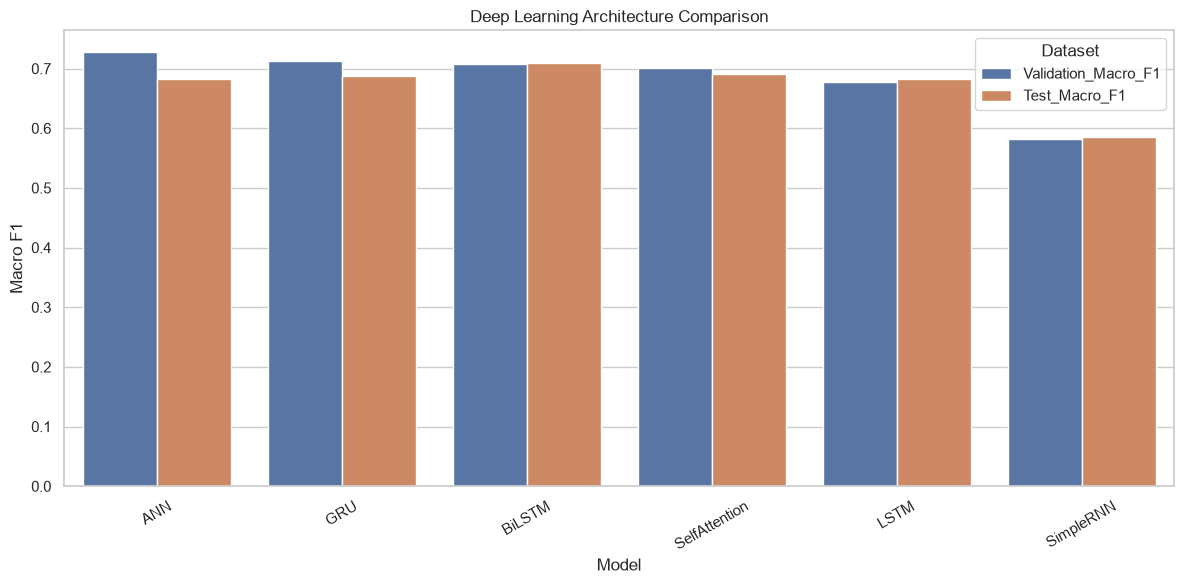

In [40]:

# ==========================================
# 32. MODEL PERFORMANCE VISUALIZATION
# ==========================================

plot_results = training_results_df.melt(
    id_vars="Model",
    value_vars=[
        "Validation_Macro_F1",
        "Test_Macro_F1"
    ],
    var_name="Dataset",
    value_name="Macro F1"
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=plot_results,
    x="Model",
    y="Macro F1",
    hue="Dataset"
)

plt.title("Deep Learning Architecture Comparison")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


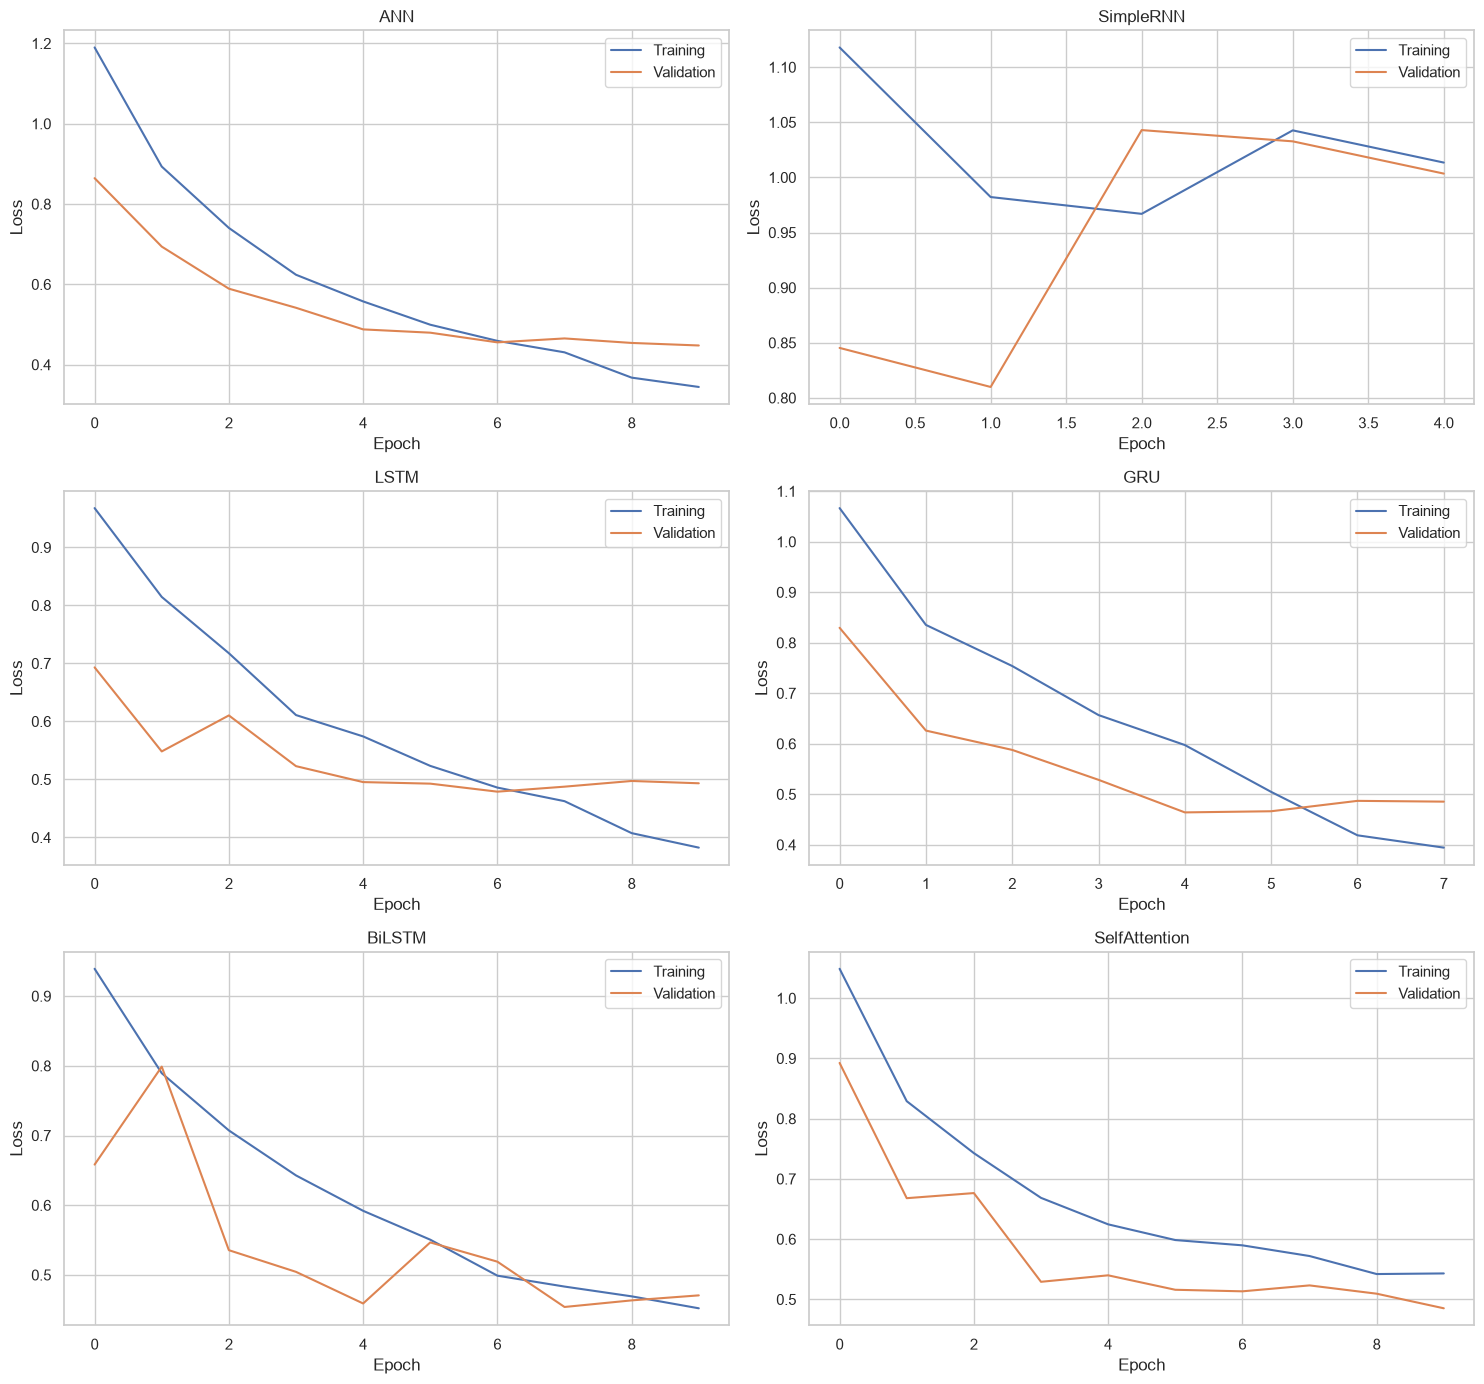

In [41]:

# ==========================================
# 33. LOSS CURVES
# ==========================================

fig, axes = plt.subplots(
    3,
    2,
    figsize=(15, 14)
)

for axis, (name, history) in zip(
    axes.flatten(),
    training_histories.items()
):

    axis.plot(history["loss"], label="Training")
    axis.plot(history["val_loss"], label="Validation")

    axis.set_title(name)
    axis.set_xlabel("Epoch")
    axis.set_ylabel("Loss")
    axis.legend()

plt.tight_layout()
plt.show()


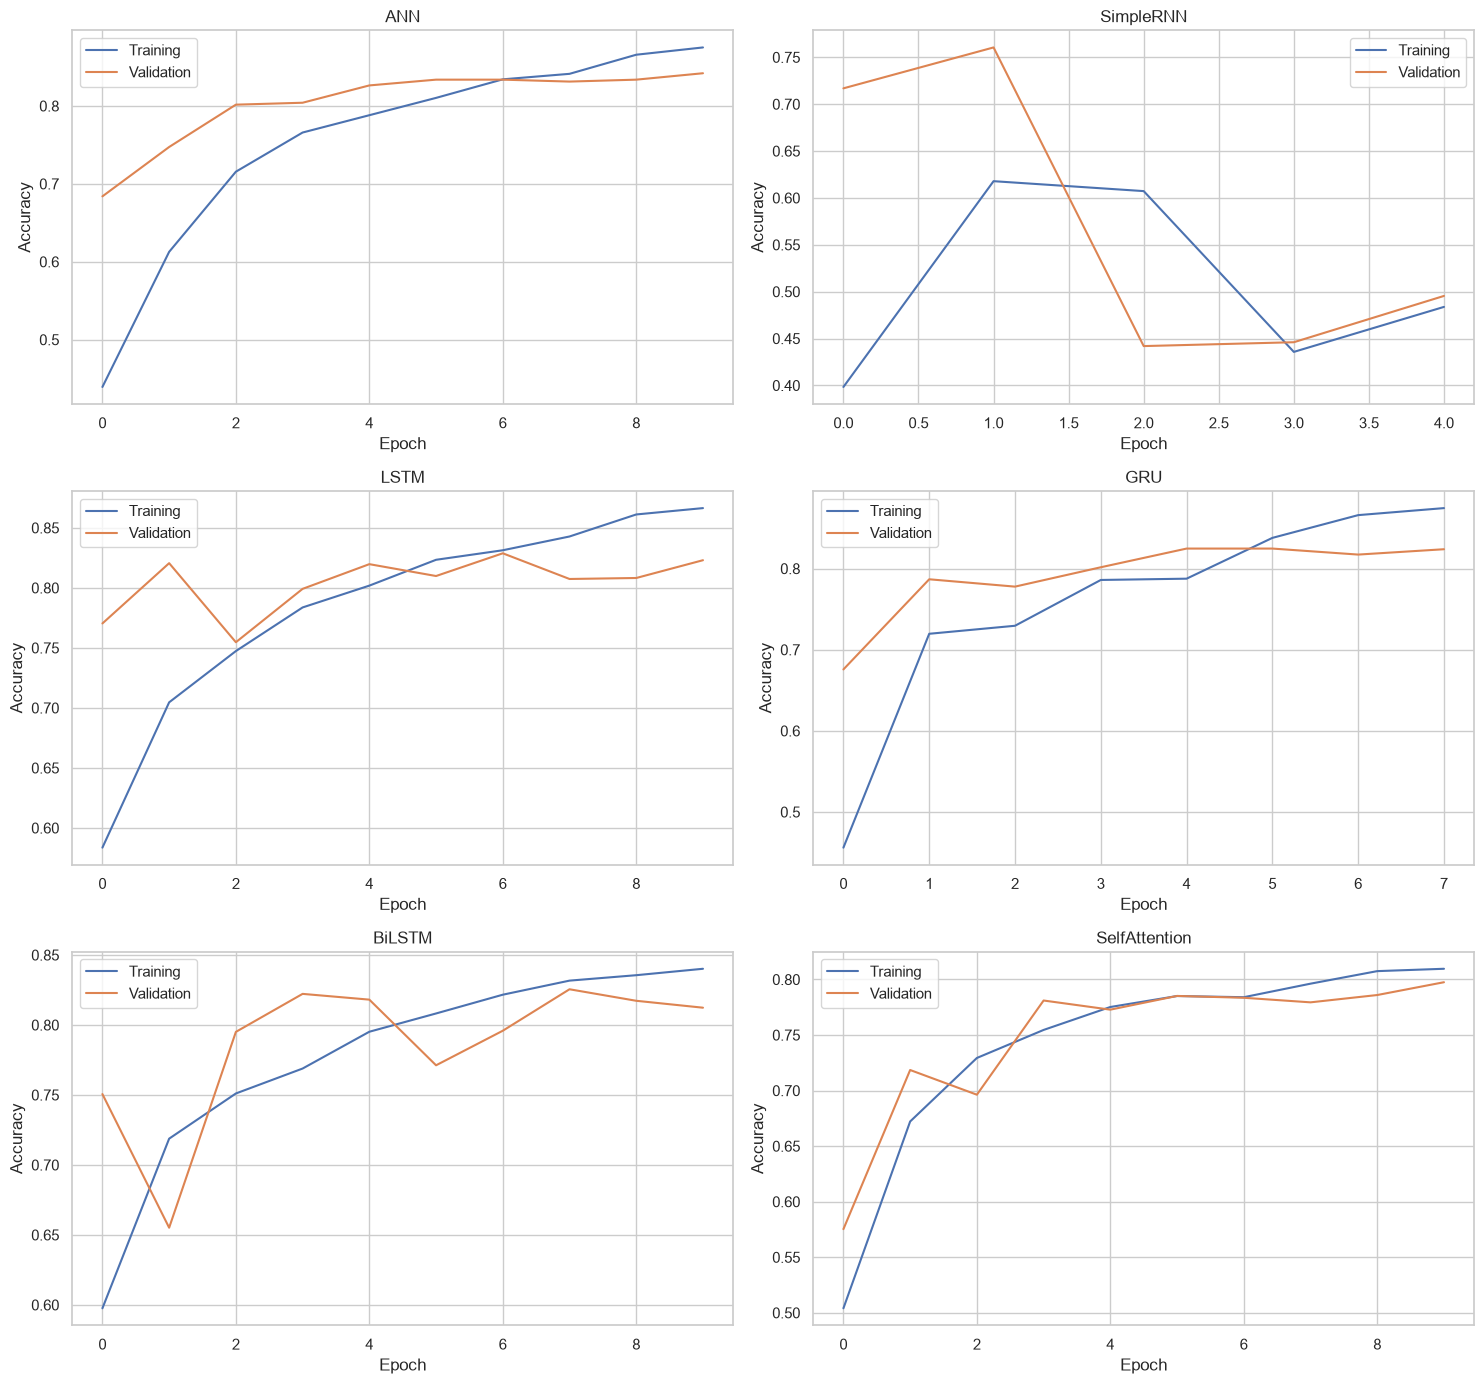

In [42]:

# ==========================================
# 34. ACCURACY CURVES
# ==========================================

fig, axes = plt.subplots(
    3,
    2,
    figsize=(15, 14)
)

for axis, (name, history) in zip(
    axes.flatten(),
    training_histories.items()
):

    axis.plot(history["accuracy"], label="Training")
    axis.plot(history["val_accuracy"], label="Validation")

    axis.set_title(name)
    axis.set_xlabel("Epoch")
    axis.set_ylabel("Accuracy")
    axis.legend()

plt.tight_layout()
plt.show()


In [43]:

# ==========================================
# 35. BEST MODEL CLASSIFICATION REPORT
# ==========================================

best_model_test_predictions = np.argmax(
    test_probabilities[best_model_name],
    axis=1
)

print("Best architecture:", best_model_name)

print(
    classification_report(
        y_test,
        best_model_test_predictions,
        labels=[0, 1, 2],
        target_names=[
            "Negative",
            "Neutral",
            "Positive"
        ],
        zero_division=0
    )
)


Best architecture: ANN
              precision    recall  f1-score   support

    Negative       0.85      0.85      0.85       511
     Neutral       0.28      0.39      0.33       117
    Positive       0.90      0.84      0.87       587

    accuracy                           0.80      1215
   macro avg       0.68      0.69      0.68      1215
weighted avg       0.82      0.80      0.81      1215



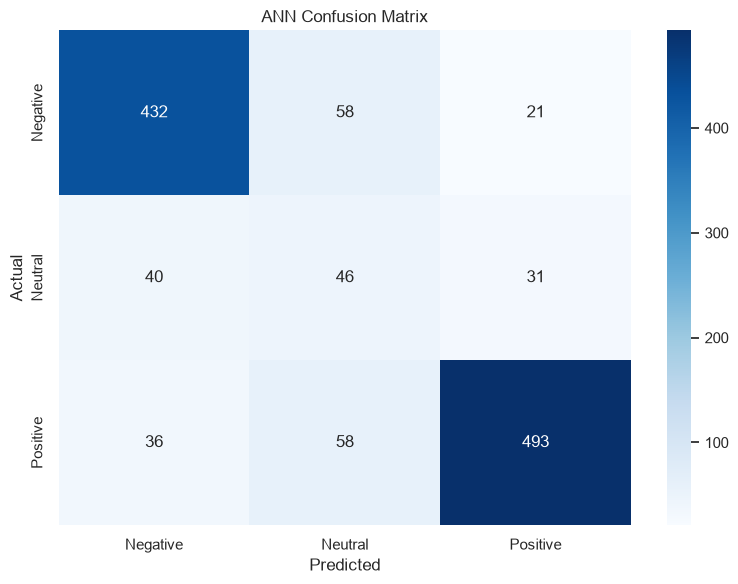

In [44]:

# ==========================================
# 36. CONFUSION MATRIX
# ==========================================

best_cm = confusion_matrix(
    y_test,
    best_model_test_predictions,
    labels=[0, 1, 2]
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    best_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Negative", "Neutral", "Positive"],
    yticklabels=["Negative", "Neutral", "Positive"]
)

plt.title(f"{best_model_name} Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.tight_layout()
plt.show()


In [45]:

# ==========================================
# 37. SAVE SENTIMENT EXPERIMENTS
# ==========================================

training_results_df.to_csv(
    DEEP_LEARNING_DIR / "sentiment_model_comparison.csv",
    index=False
)

prediction_data = {}

for name, probabilities in validation_probabilities.items():

    prediction_data[f"{name}_validation"] = probabilities

for name, probabilities in test_probabilities.items():

    prediction_data[f"{name}_test"] = probabilities

np.savez_compressed(
    DEEP_LEARNING_DIR / "sentiment_model_probabilities.npz",
    **prediction_data
)

np.savez_compressed(
    DEEP_LEARNING_DIR / "sentiment_split_indices.npz",

    train_indices=train_indices,
    validation_indices=val_indices,
    test_indices=test_indices,

    y_train=y_train,
    y_validation=y_val,
    y_test=y_test
)

print("Sentiment models and predictions saved.")


Sentiment models and predictions saved.


In [46]:

# ==========================================
# 38. TENSORBOARD
# ==========================================

%load_ext tensorboard
%tensorboard --logdir "{TENSORBOARD_DIR.as_posix()}"


## Stage 8 — Classical ML baselines

In [47]:

# ==========================================
# 39. CLASSICAL NLP VECTORIZATION
# ==========================================

classical_vectorizer = TfidfVectorizer(
    max_features=30000,
    min_df=2,
    max_df=0.98,
    ngram_range=(1, 2),
    sublinear_tf=True
)

X_train_classical = classical_vectorizer.fit_transform(
    X_train_text
)

X_val_classical = classical_vectorizer.transform(
    X_val_text
)

X_test_classical = classical_vectorizer.transform(
    X_test_text
)

print("Training:", X_train_classical.shape)
print("Validation:", X_val_classical.shape)
print("Testing:", X_test_classical.shape)


Training: (5668, 30000)
Validation: (1215, 30000)
Testing: (1215, 30000)


In [49]:
# ==========================================
# 40. CLASSICAL ML CLASSIFIERS
# ==========================================

from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB

classical_models = {
    "LogisticRegression": LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=RANDOM_STATE
    ),
    "NaiveBayes": MultinomialNB(
        alpha=0.5
    )
}

classical_validation_probabilities = {}
classical_test_probabilities = {}

classical_results = []

for name, model in classical_models.items():
    print("\nTraining:", name)

    model.fit(
        X_train_classical,
        y_train
    )

    # Ensure probability columns are ordered as 0, 1, 2
    def aligned_probabilities(model, features):
        raw = model.predict_proba(features)

        # FIX: Use features.shape[0] instead of len(features) for sparse compatibility
        aligned = np.zeros(
            (features.shape[0], NUM_SENTIMENT_CLASSES),
            dtype=np.float64
        )

        for position, class_id in enumerate(model.classes_):
            aligned[:, int(class_id)] = raw[:, position]

        return aligned

    val_probs = aligned_probabilities(
        model,
        X_val_classical
    )

    test_probs = aligned_probabilities(
        model,
        X_test_classical
    )

    classical_validation_probabilities[name] = val_probs
    classical_test_probabilities[name] = test_probs

    val_metrics = calculate_classification_metrics(
        y_val,
        val_probs
    )

    test_metrics = calculate_classification_metrics(
        y_test,
        test_probs
    )

    classical_results.append({
        "Model": name,
        "Validation_Accuracy": val_metrics["Accuracy"],
        "Validation_Macro_F1": val_metrics["F1_Macro"],
        "Test_Accuracy": test_metrics["Accuracy"],
        "Test_Macro_F1": test_metrics["F1_Macro"]
    })

    joblib.dump(
        model,
        CLASSICAL_DIR / f"{name.lower()}_sentiment.joblib"
    )

    print("Validation Macro F1:", round(val_metrics["F1_Macro"], 4))
    print("Test Macro F1:", round(test_metrics["F1_Macro"], 4))

classical_results_df = pd.DataFrame(classical_results)

display(classical_results_df.round(4))


Training: LogisticRegression
Validation Macro F1: 0.7312
Test Macro F1: 0.6953

Training: NaiveBayes
Validation Macro F1: 0.5648
Test Macro F1: 0.5716


,Model,Validation_Accuracy,Validation_Macro_F1,Test_Accuracy,Test_Macro_F1
0,LogisticRegression,0.8486,0.7312,0.8189,0.6953
1,NaiveBayes,0.8066,0.5648,0.8156,0.5716


In [50]:

# ==========================================
# 41. SAVE CLASSICAL ARTIFACTS
# ==========================================

joblib.dump(
    classical_vectorizer,
    CLASSICAL_DIR / "classical_tfidf_vectorizer.joblib"
)

np.savez_compressed(
    DEEP_LEARNING_DIR / "classical_probabilities.npz",

    **{
        f"{name}_validation": probabilities
        for name, probabilities
        in classical_validation_probabilities.items()
    },

    **{
        f"{name}_test": probabilities
        for name, probabilities
        in classical_test_probabilities.items()
    }
)

print("Classical models and vectorizer saved.")


Classical models and vectorizer saved.


## Stage 9 — Ensemble learning

In [51]:

# ==========================================
# 42. COLLECT ALL MODEL PROBABILITIES
# ==========================================

all_validation_probabilities = {
    **validation_probabilities,
    **classical_validation_probabilities
}

all_test_probabilities = {
    **test_probabilities,
    **classical_test_probabilities
}

assert set(all_validation_probabilities) == set(
    all_test_probabilities
)

for name in all_validation_probabilities:

    assert all_validation_probabilities[name].shape == (
        len(y_val),
        NUM_SENTIMENT_CLASSES
    )

    assert all_test_probabilities[name].shape == (
        len(y_test),
        NUM_SENTIMENT_CLASSES
    )

print("Models available for ensemble:")

for name in all_validation_probabilities:
    print("-", name)


Models available for ensemble:
- ANN
- SimpleRNN
- LSTM
- GRU
- BiLSTM
- SelfAttention
- LogisticRegression
- NaiveBayes


In [52]:

# ==========================================
# 43. INDIVIDUAL MODEL COMPARISON
# ==========================================

individual_model_results = []

for name, probabilities in all_validation_probabilities.items():

    metrics = calculate_classification_metrics(
        y_val,
        probabilities
    )

    individual_model_results.append({
        "Model": name,
        "Validation_Accuracy": metrics["Accuracy"],
        "Validation_Macro_F1": metrics["F1_Macro"]
    })


individual_results_df = (
    pd.DataFrame(individual_model_results)
    .sort_values(
        "Validation_Macro_F1",
        ascending=False
    )
    .reset_index(drop=True)
)

display(individual_results_df.round(4))


,Model,Validation_Accuracy,Validation_Macro_F1
0,LogisticRegression,0.8486,0.7312
1,ANN,0.8420,0.7276
2,GRU,0.8247,0.7127
3,BiLSTM,0.8123,0.7070
4,SelfAttention,0.7975,0.7016
5,LSTM,0.8288,0.6770
6,SimpleRNN,0.7605,0.5818
7,NaiveBayes,0.8066,0.5648


In [53]:

# ==========================================
# 44. HARD VOTING
# ==========================================

def hard_voting_predict(probability_dict):

    predictions = np.stack([
        np.argmax(probabilities, axis=1)
        for probabilities in probability_dict.values()
    ])

    final_predictions = []

    for sample_index in range(predictions.shape[1]):

        votes = np.bincount(
            predictions[:, sample_index],
            minlength=NUM_SENTIMENT_CLASSES
        )

        winners = np.flatnonzero(
            votes == votes.max()
        )

        if len(winners) == 1:

            final_predictions.append(winners[0])

        else:

            average_probabilities = np.mean(
                [
                    probabilities[sample_index]
                    for probabilities in probability_dict.values()
                ],
                axis=0
            )

            final_predictions.append(
                winners[
                    np.argmax(average_probabilities[winners])
                ]
            )

    return np.array(final_predictions)


hard_val_predictions = hard_voting_predict(
    all_validation_probabilities
)

hard_test_predictions = hard_voting_predict(
    all_test_probabilities
)


print("Validation hard voting Macro F1:",
      f1_score(y_val, hard_val_predictions, average="macro"))

print("Test hard voting Macro F1:",
      f1_score(y_test, hard_test_predictions, average="macro"))


Validation hard voting Macro F1: 0.7149217671451602
Test hard voting Macro F1: 0.7057694378979225


In [54]:

# ==========================================
# 45. SOFT VOTING
# ==========================================

def soft_voting_predict(probability_dict):

    return np.mean(
        np.stack(list(probability_dict.values())),
        axis=0
    )


soft_val_probabilities = soft_voting_predict(
    all_validation_probabilities
)

soft_test_probabilities = soft_voting_predict(
    all_test_probabilities
)

soft_val_metrics = calculate_classification_metrics(
    y_val,
    soft_val_probabilities
)

soft_test_metrics = calculate_classification_metrics(
    y_test,
    soft_test_probabilities
)

print("Validation Macro F1:", soft_val_metrics["F1_Macro"])
print("Test Macro F1:", soft_test_metrics["F1_Macro"])


Validation Macro F1: 0.7092545780866112
Test Macro F1: 0.7116129737192867


In [55]:

# ==========================================
# 46. VALIDATION-BASED WEIGHTED ENSEMBLE
# ==========================================

TOP_ENSEMBLE_MODELS = 4

selected_ensemble_models = (
    individual_results_df
    .head(TOP_ENSEMBLE_MODELS)["Model"]
    .tolist()
)

print("Selected models:")

for name in selected_ensemble_models:
    print("-", name)


# Obtain validation scores for selected models
selected_scores = np.array([
    all_validation_probabilities[name]
    for name in selected_ensemble_models
])

# Use squared Macro F1 to emphasize stronger models
validation_scores = np.array([
    individual_results_df.loc[
        individual_results_df["Model"] == name,
        "Validation_Macro_F1"
    ].iloc[0]
    for name in selected_ensemble_models
])

weights = np.square(validation_scores)

# Normalize weights
weights = weights / weights.sum()

ensemble_weights = {
    name: float(weight)
    for name, weight in zip(
        selected_ensemble_models,
        weights
    )
}

print("\nEnsemble weights:")

for name, weight in ensemble_weights.items():
    print(name, ":", round(weight, 4))


def weighted_ensemble_predict(
    probability_dict,
    model_weights
):

    result = None

    for name, weight in model_weights.items():

        contribution = (
            probability_dict[name] * weight
        )

        if result is None:
            result = contribution.copy()
        else:
            result += contribution

    return result


weighted_val_probabilities = weighted_ensemble_predict(
    all_validation_probabilities,
    ensemble_weights
)

weighted_test_probabilities = weighted_ensemble_predict(
    all_test_probabilities,
    ensemble_weights
)

print(
    "\nValidation Macro F1:",
    f1_score(
        y_val,
        np.argmax(weighted_val_probabilities, axis=1),
        average="macro"
    )
)

print(
    "Test Macro F1:",
    f1_score(
        y_test,
        np.argmax(weighted_test_probabilities, axis=1),
        average="macro"
    )
)


Selected models:
- LogisticRegression
- ANN
- GRU
- BiLSTM

Ensemble weights:
LogisticRegression : 0.258
ANN : 0.2555
GRU : 0.2452
BiLSTM : 0.2413

Validation Macro F1: 0.734363635254458
Test Macro F1: 0.7110165239492355


In [56]:

# ==========================================
# 47. ENSEMBLE PERFORMANCE COMPARISON
# ==========================================

ensemble_results = []

# Individual models
for name, probabilities in all_validation_probabilities.items():

    val_metrics = calculate_classification_metrics(
        y_val,
        probabilities
    )

    test_metrics = calculate_classification_metrics(
        y_test,
        all_test_probabilities[name]
    )

    ensemble_results.append({

        "Model": name,

        "Type": "Individual",

        "Validation_Macro_F1": val_metrics["F1_Macro"],

        "Test_Macro_F1": test_metrics["F1_Macro"]

    })


# Hard voting
ensemble_results.append({

    "Model": "Hard Voting",

    "Type": "Ensemble",

    "Validation_Macro_F1": f1_score(
        y_val,
        hard_val_predictions,
        average="macro"
    ),

    "Test_Macro_F1": f1_score(
        y_test,
        hard_test_predictions,
        average="macro"
    )

})


# Soft voting
ensemble_results.append({

    "Model": "Soft Voting",

    "Type": "Ensemble",

    "Validation_Macro_F1": soft_val_metrics["F1_Macro"],

    "Test_Macro_F1": soft_test_metrics["F1_Macro"]

})


# Weighted voting
ensemble_results.append({

    "Model": "Weighted Soft Voting",

    "Type": "Ensemble",

    "Validation_Macro_F1": f1_score(
        y_val,
        np.argmax(weighted_val_probabilities, axis=1),
        average="macro"
    ),

    "Test_Macro_F1": f1_score(
        y_test,
        np.argmax(weighted_test_probabilities, axis=1),
        average="macro"
    )

})


ensemble_results_df = (
    pd.DataFrame(ensemble_results)
    .sort_values(
        "Validation_Macro_F1",
        ascending=False
    )
    .reset_index(drop=True)
)

display(ensemble_results_df.round(4))


,Model,Type,Validation_Macro_F1,Test_Macro_F1
0,Weighted Soft Voting,Ensemble,0.7344,0.7110
1,LogisticRegression,Individual,0.7312,0.6953
2,ANN,Individual,0.7276,0.6829
3,Hard Voting,Ensemble,0.7149,0.7058
4,GRU,Individual,0.7127,0.6871
5,Soft Voting,Ensemble,0.7093,0.7116
6,BiLSTM,Individual,0.7070,0.7098
7,SelfAttention,Individual,0.7016,0.6917
8,LSTM,Individual,0.6770,0.6825
9,SimpleRNN,Individual,0.5818,0.5848


In [57]:

# ==========================================
# 48. FINAL SENTIMENT MODEL SELECTION
# ==========================================

best_result = ensemble_results_df.iloc[0]

best_sentiment_choice = best_result["Model"]

print("Selected sentiment system:", best_sentiment_choice)

if best_sentiment_choice == "Hard Voting":

    final_sentiment_validation = hard_val_predictions
    final_sentiment_test = hard_test_predictions

    final_sentiment_validation_probabilities = None
    final_sentiment_test_probabilities = None

elif best_sentiment_choice == "Soft Voting":

    final_sentiment_validation_probabilities = soft_val_probabilities
    final_sentiment_test_probabilities = soft_test_probabilities

    final_sentiment_validation = np.argmax(
        soft_val_probabilities,
        axis=1
    )

    final_sentiment_test = np.argmax(
        soft_test_probabilities,
        axis=1
    )

elif best_sentiment_choice == "Weighted Soft Voting":

    final_sentiment_validation_probabilities = weighted_val_probabilities
    final_sentiment_test_probabilities = weighted_test_probabilities

    final_sentiment_validation = np.argmax(
        weighted_val_probabilities,
        axis=1
    )

    final_sentiment_test = np.argmax(
        weighted_test_probabilities,
        axis=1
    )

else:

    final_sentiment_validation_probabilities = (
        all_validation_probabilities[best_sentiment_choice]
    )

    final_sentiment_test_probabilities = (
        all_test_probabilities[best_sentiment_choice]
    )

    final_sentiment_validation = np.argmax(
        final_sentiment_validation_probabilities,
        axis=1
    )

    final_sentiment_test = np.argmax(
        final_sentiment_test_probabilities,
        axis=1
    )


print("\nFINAL TEST CLASSIFICATION REPORT")

print(
    classification_report(
        y_test,
        final_sentiment_test,
        labels=[0, 1, 2],
        target_names=[
            "Negative",
            "Neutral",
            "Positive"
        ],
        zero_division=0
    )
)


Selected sentiment system: Weighted Soft Voting

FINAL TEST CLASSIFICATION REPORT
              precision    recall  f1-score   support

    Negative       0.89      0.87      0.88       511
     Neutral       0.32      0.41      0.36       117
    Positive       0.91      0.87      0.89       587

    accuracy                           0.83      1215
   macro avg       0.71      0.72      0.71      1215
weighted avg       0.84      0.83      0.84      1215



In [58]:

# ==========================================
# 49. SAVE SENTIMENT ENSEMBLE
# ==========================================

ensemble_config = {

    "selected_system": best_sentiment_choice,

    "selected_models": selected_ensemble_models,

    "weights": ensemble_weights,

    "sentiment_mapping": SENTIMENT_TO_ID,

    "classes": [
        "Negative",
        "Neutral",
        "Positive"
    ],

    "selection_metric": "Validation Macro F1"

}

ENSEMBLE_CONFIG_PATH = (
    DEEP_LEARNING_DIR /
    "sentiment_ensemble_config.json"
)

ENSEMBLE_CONFIG_PATH.write_text(
    json.dumps(ensemble_config, indent=4),
    encoding="utf-8"
)

print("Ensemble configuration saved.")


Ensemble configuration saved.


## Stage 10 — Recommendation prediction

In [59]:
# ==========================================
# 50. RECOMMENDATION CLASS WEIGHTS
# ==========================================
recommendation_classes = np.unique(y_train_rec)
recommendation_weights = compute_class_weight(
    class_weight="balanced",
    classes=recommendation_classes,
    y=y_train_rec
)
recommendation_class_weights = {
    int(class_id): float(weight)
    for class_id, weight in zip(
        recommendation_classes,
        recommendation_weights
    )
}
print("Recommendation class weights:")
for class_id, weight in recommendation_class_weights.items():
    print(
        recommendation_mapping[class_id],
        "->",
        round(weight, 4)
    )

Recommendation class weights:
Not Recommended -> 1.0618
Recommended -> 0.945


In [60]:
# ==========================================
# 51. SELECT RECOMMENDATION ARCHITECTURES
# ==========================================
deep_learning_names = [
    "ANN",
    "SimpleRNN",
    "LSTM",
    "GRU",
    "BiLSTM",
    "SelfAttention"
]
top_recommendation_models = (
    training_results_df[
        training_results_df["Model"].isin(
            deep_learning_names
        )
    ]
    .sort_values(
        "Validation_Macro_F1",
        ascending=False
    )
    .head(3)["Model"]
    .tolist()
)
print("Selected recommendation architectures:")
for name in top_recommendation_models:
    print("-", name)

Selected recommendation architectures:
- ANN
- GRU
- BiLSTM


In [61]:
# ==========================================
# 52. BUILD BINARY RECOMMENDATION MODELS
# ==========================================
def build_recommendation_model(architecture):
    if architecture == "ANN":
        model = build_ann_model(
            input_dimensions=X_train_ann.shape[1],
            binary=True
        )
    elif architecture in [
        "SimpleRNN",
        "LSTM",
        "GRU",
        "BiLSTM"
    ]:
        model = build_recurrent_model(
            architecture,
            binary=True
        )
    elif architecture == "SelfAttention":
        model = build_attention_model(
            binary=True
        )
    else:
        raise ValueError(
            f"Unknown architecture: {architecture}"
        )
        
    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=LEARNING_RATE
        ),
        loss="binary_crossentropy",
        metrics=[
            "accuracy",
            tf.keras.metrics.AUC(name="auc")
        ]
    )
    return model

recommendation_models = {}
for name in top_recommendation_models:
    recommendation_models[name] = (
        build_recommendation_model(name)
    )
    print("\n", name)
    recommendation_models[name].summary()


 ANN
Model: "FlightAura_ANN"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_7 (InputLayer)        [(None, 200)]             0         
                                                                 
 dense_16 (Dense)            (None, 256)               51456     
                                                                 
 dropout_12 (Dropout)        (None, 256)               0         
                                                                 
 dense_17 (Dense)            (None, 128)               32896     
                                                                 
 dropout_13 (Dropout)        (None, 128)               0         
                                                                 
 dense_18 (Dense)            (None, 1)                 129       
                                                                 
Total params: 84481 (330.00 KB)
Trainable para

In [62]:
# ==========================================
# 53. TRAIN RECOMMENDATION MODELS
# ==========================================
recommendation_histories = {}
recommendation_validation_probabilities = {}
recommendation_test_probabilities = {}
recommendation_results = {}
trained_recommendation_models = {}

for name, model in recommendation_models.items():
    print("\n" + "=" * 75)
    print("TRAINING RECOMMENDATION MODEL:", name)
    print("=" * 75)
    start_time = time.perf_counter()
    
    if name == "ANN":
        X_train_input = X_train_ann
        X_val_input = X_val_ann
        X_test_input = X_test_ann
    else:
        X_train_input = X_train_seq
        X_val_input = X_val_seq
        X_test_input = X_test_seq
        
    history = model.fit(
        X_train_input,
        y_train_rec,
        validation_data=(
            X_val_input,
            y_val_rec
        ),
        epochs=MAX_EPOCHS,
        batch_size=BATCH_SIZE,
        class_weight=recommendation_class_weights,
        callbacks=create_training_callbacks(
            "recommendation_" + name
        ),
        verbose=1
    )
    elapsed = time.perf_counter() - start_time
    
    # Save model
    model_path = (
        DEEP_LEARNING_DIR /
        f"{name.lower()}_recommendation.keras"
    )
    model.save(model_path)
    trained_recommendation_models[name] = model
    recommendation_histories[name] = history.history
    
    # Predict probabilities
    val_probs = model.predict(
        X_val_input,
        batch_size=BATCH_SIZE,
        verbose=0
    ).ravel()
    test_probs = model.predict(
        X_test_input,
        batch_size=BATCH_SIZE,
        verbose=0
    ).ravel()
    
    recommendation_validation_probabilities[name] = val_probs
    recommendation_test_probabilities[name] = test_probs
    
    val_predictions = (val_probs >= 0.5).astype(int)
    test_predictions = (test_probs >= 0.5).astype(int)
    
    val_f1 = f1_score(
        y_val_rec,
        val_predictions,
        average="macro",
        zero_division=0
    )
    test_f1 = f1_score(
        y_test_rec,
        test_predictions,
        average="macro",
        zero_division=0
    )
    
    recommendation_results[name] = {
        "Model": name,
        "Training_Time_Seconds": round(elapsed, 2),
        "Validation_Accuracy": accuracy_score(
            y_val_rec,
            val_predictions
        ),
        "Validation_Macro_F1": val_f1,
        "Test_Accuracy": accuracy_score(
            y_test_rec,
            test_predictions
        ),
        "Test_Macro_F1": test_f1
    }
    
    print("Validation Macro F1:", round(val_f1, 4))
    print("Test Macro F1:", round(test_f1, 4))
    print("Saved:", model_path)

recommendation_results_df = pd.DataFrame(
    recommendation_results.values()
)
recommendation_results_df = (
    recommendation_results_df
    .sort_values(
        "Validation_Macro_F1",
        ascending=False
    )
    .reset_index(drop=True)
)
display(recommendation_results_df.round(4))


TRAINING RECOMMENDATION MODEL: ANN
Epoch 1/10
89/89 [==============================] - 2s 8ms/step - loss: 0.6177 - accuracy: 0.6706 - auc: 0.7335 - val_loss: 0.3586 - val_accuracy: 0.8831 - val_auc: 0.9473 - lr: 0.0010
Epoch 2/10
89/89 [==============================] - 0s 4ms/step - loss: 0.3771 - accuracy: 0.8336 - auc: 0.9118 - val_loss: 0.2659 - val_accuracy: 0.8947 - val_auc: 0.9609 - lr: 0.0010
Epoch 3/10
89/89 [==============================] - 0s 5ms/step - loss: 0.2887 - accuracy: 0.8788 - auc: 0.9489 - val_loss: 0.2569 - val_accuracy: 0.8922 - val_auc: 0.9612 - lr: 0.0010
Epoch 4/10
89/89 [==============================] - 1s 6ms/step - loss: 0.2413 - accuracy: 0.9030 - auc: 0.9642 - val_loss: 0.2467 - val_accuracy: 0.9021 - val_auc: 0.9624 - lr: 0.0010
Epoch 5/10
80/89 [=========================>....] - ETA: 0s - loss: 0.2168 - accuracy: 0.9104 - auc: 0.9708
Epoch 5: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
89/89 [==============================] -

,Model,Training_Time_Seconds,Validation_Accuracy,Validation_Macro_F1,Test_Accuracy,Test_Macro_F1
0,BiLSTM,302.69,0.9103,0.9101,0.8979,0.8979
1,GRU,171.02,0.9045,0.9043,0.8963,0.8961
2,ANN,4.97,0.9021,0.9017,0.8947,0.8945


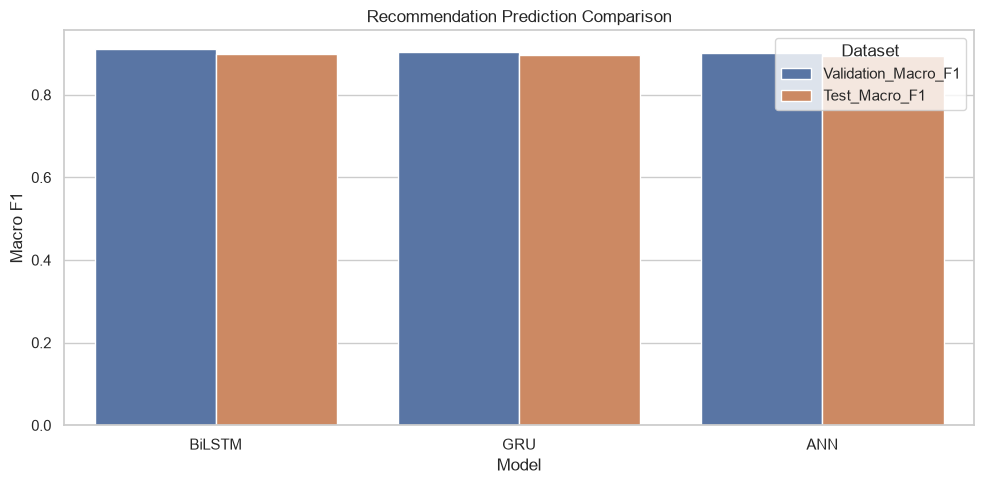

In [63]:
# ==========================================
# 54. RECOMMENDATION MODEL COMPARISON
# ==========================================
recommendation_plot = recommendation_results_df.melt(
    id_vars="Model",
    value_vars=[
        "Validation_Macro_F1",
        "Test_Macro_F1"
    ],
    var_name="Dataset",
    value_name="Macro F1"
)
plt.figure(figsize=(10, 5))
sns.barplot(
    data=recommendation_plot,
    x="Model",
    y="Macro F1",
    hue="Dataset"
)
plt.title("Recommendation Prediction Comparison")
plt.tight_layout()
plt.show()

In [64]:
# ==========================================
# 55. BEST RECOMMENDATION MODEL
# ==========================================
best_recommendation_name = (
    recommendation_results_df.iloc[0]["Model"]
)
best_recommendation_model = (
    trained_recommendation_models[
        best_recommendation_name
    ]
)
print("Best recommendation architecture:")
print(best_recommendation_name)

val_probs = recommendation_validation_probabilities[
    best_recommendation_name
]
test_probs = recommendation_test_probabilities[
    best_recommendation_name
]

val_predictions = (val_probs >= 0.5).astype(int)
test_predictions = (test_probs >= 0.5).astype(int)

print("\nTEST CLASSIFICATION REPORT")
print(
    classification_report(
        y_test_rec,
        test_predictions,
        labels=[0, 1],
        target_names=[
            "Not Recommended",
            "Recommended"
        ],
        zero_division=0
    )
)

Best recommendation architecture:
BiLSTM

TEST CLASSIFICATION REPORT
                 precision    recall  f1-score   support

Not Recommended       0.87      0.92      0.90       574
    Recommended       0.93      0.88      0.90       641

       accuracy                           0.90      1215
      macro avg       0.90      0.90      0.90      1215
   weighted avg       0.90      0.90      0.90      1215



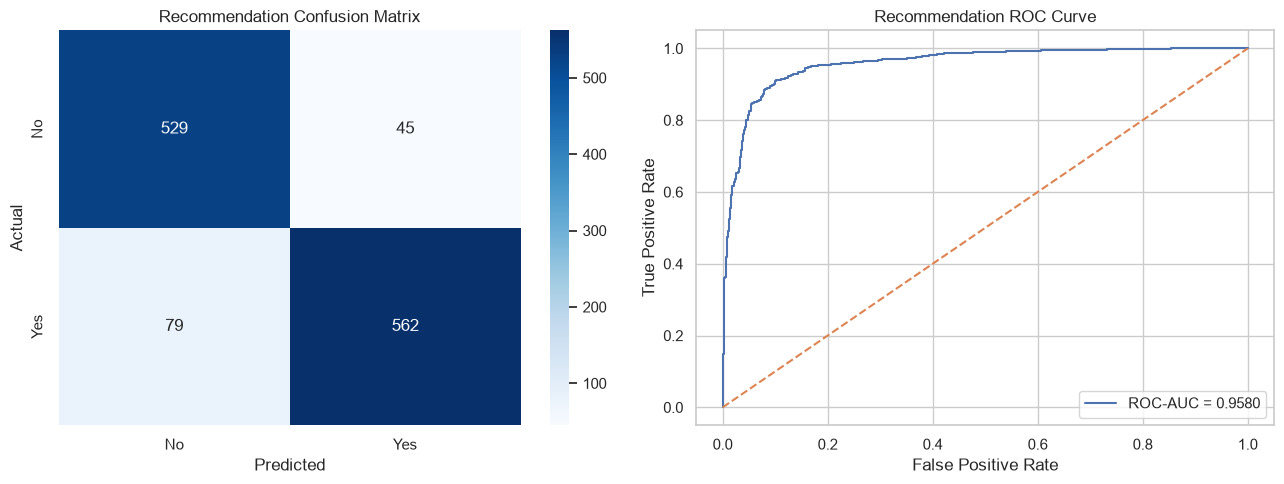

Recommendation Test ROC-AUC: 0.958


In [65]:
# ==========================================
# 56. RECOMMENDATION EVALUATION
# ==========================================
from sklearn.metrics import roc_auc_score, roc_curve

recommendation_cm = confusion_matrix(
    y_test_rec,
    test_predictions,
    labels=[0, 1]
)

fig, axes = plt.subplots(
    1,
    2,
    figsize=(13, 5)
)

sns.heatmap(
    recommendation_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No", "Yes"],
    yticklabels=["No", "Yes"],
    ax=axes[0]
)
axes[0].set_title("Recommendation Confusion Matrix")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")

fpr, tpr, thresholds = roc_curve(
    y_test_rec,
    test_probs
)
roc_auc = roc_auc_score(
    y_test_rec,
    test_probs
)

axes[1].plot(
    fpr,
    tpr,
    label=f"ROC-AUC = {roc_auc:.4f}"
)
axes[1].plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)
axes[1].set_title("Recommendation ROC Curve")
axes[1].set_xlabel("False Positive Rate")
axes[1].set_ylabel("True Positive Rate")
axes[1].legend()

plt.tight_layout()
plt.show()

print("Recommendation Test ROC-AUC:", round(roc_auc, 4))

In [66]:
# ==========================================
# 57. RECOMMENDATION WEIGHTED ENSEMBLE
# ==========================================
recommendation_validation_scores = np.array([
    recommendation_results[name]["Validation_Macro_F1"]
    for name in top_recommendation_models
])
recommendation_weights = (
    recommendation_validation_scores ** 2
)
recommendation_weights = (
    recommendation_weights /
    recommendation_weights.sum()
)
recommendation_ensemble_weights = {
    name: float(weight)
    for name, weight in zip(
        top_recommendation_models,
        recommendation_weights
    )
}

print("Recommendation ensemble weights:")
for name, weight in recommendation_ensemble_weights.items():
    print(name, ":", round(weight, 4))
    
def weighted_binary_ensemble(probability_dict, weights):
    result = np.zeros(
        len(next(iter(probability_dict.values()))),
        dtype=np.float64
    )
    for name, weight in weights.items():
        result += probability_dict[name] * weight
    return result

recommendation_ensemble_val = weighted_binary_ensemble(
    recommendation_validation_probabilities,
    recommendation_ensemble_weights
)
recommendation_ensemble_test = weighted_binary_ensemble(
    recommendation_test_probabilities,
    recommendation_ensemble_weights
)

ensemble_val_predictions = (
    recommendation_ensemble_val >= 0.5
).astype(int)
ensemble_test_predictions = (
    recommendation_ensemble_test >= 0.5
).astype(int)

print(
    "\nRecommendation ensemble validation Macro F1:",
    f1_score(
        y_val_rec,
        ensemble_val_predictions,
        average="macro"
    )
)
print(
    "Recommendation ensemble test Macro F1:",
    f1_score(
        y_test_rec,
        ensemble_test_predictions,
        average="macro"
    )
)

Recommendation ensemble weights:
ANN : 0.3306
GRU : 0.3325
BiLSTM : 0.3368

Recommendation ensemble validation Macro F1: 0.9092653240786001
Recommendation ensemble test Macro F1: 0.9027804901865053


In [67]:
# ==========================================
# 58. FINAL RECOMMENDATION SYSTEM SELECTION
# ==========================================
individual_best_f1 = (
    recommendation_results_df.iloc[0]["Validation_Macro_F1"]
)
ensemble_validation_f1 = f1_score(
    y_val_rec,
    ensemble_val_predictions,
    average="macro"
)

if ensemble_validation_f1 > individual_best_f1:
    best_recommendation_choice = "Weighted Ensemble"
    final_recommendation_validation = recommendation_ensemble_val
    final_recommendation_test = recommendation_ensemble_test
else:
    best_recommendation_choice = best_recommendation_name
    final_recommendation_validation = (
        recommendation_validation_probabilities[
            best_recommendation_name
        ]
    )
    final_recommendation_test = (
        recommendation_test_probabilities[
            best_recommendation_name
        ]
    )
    
print("Selected recommendation system:")
print(best_recommendation_choice)

final_rec_predictions = (
    final_recommendation_test >= 0.5
).astype(int)

print("\nFinal recommendation test Macro F1:")
print(
    f1_score(
        y_test_rec,
        final_rec_predictions,
        average="macro"
    )
)

Selected recommendation system:
BiLSTM

Final recommendation test Macro F1:
0.8978670441233894


## Stage 11 — Save all final artifacts

In [68]:
# ==========================================
# 59. SAVE RECOMMENDATION ARTIFACTS
# ==========================================
recommendation_results_df.to_csv(
    DEEP_LEARNING_DIR / "recommendation_model_comparison.csv",
    index=False
)

recommendation_config = {
    "selected_system": best_recommendation_choice,
    "selected_model": best_recommendation_name,
    "ensemble_models": top_recommendation_models,
    "ensemble_weights": recommendation_ensemble_weights,
    "threshold": 0.5,
    "classes": {
        "0": "Not Recommended",
        "1": "Recommended"
    },
    "selection_metric": "Validation Macro F1"
}

recommendation_config_path = (
    DEEP_LEARNING_DIR /
    "recommendation_config.json"
)

recommendation_config_path.write_text(
    json.dumps(
        recommendation_config,
        indent=4
    ),
    encoding="utf-8"
)

# Save validation and test predictions
np.savez_compressed(
    DEEP_LEARNING_DIR / "recommendation_probabilities.npz",
    **{
        f"{name}_validation": probabilities
        for name, probabilities
        in recommendation_validation_probabilities.items()
    },
    **{
        f"{name}_test": probabilities
        for name, probabilities
        in recommendation_test_probabilities.items()
    },
    ensemble_validation=recommendation_ensemble_val,
    ensemble_test=recommendation_ensemble_test
)

print("Recommendation models saved.")
print("Recommendation configuration saved.")
print("Recommendation probabilities saved.")

Recommendation models saved.
Recommendation configuration saved.
Recommendation probabilities saved.


In [69]:
# ==========================================
# 60. SAVE FINAL SENTIMENT CONFIGURATION
# ==========================================
final_sentiment_config = {
    "selected_system": best_sentiment_choice,
    "selected_individual_model": (
        best_sentiment_choice
        if best_sentiment_choice in all_validation_probabilities
        else None
    ),
    "selected_ensemble_models": selected_ensemble_models,
    "ensemble_weights": ensemble_weights,
    "class_mapping": {
        "0": "Negative",
        "1": "Neutral",
        "2": "Positive"
    },
    "selection_metric": "Validation Macro F1",
    "max_sequence_length": MAX_SEQUENCE_LENGTH,
    "vocabulary_size": VOCAB_SIZE,
    "embedding_dimension": EMBEDDING_DIM
}

FINAL_SENTIMENT_CONFIG_PATH = (
    DEEP_LEARNING_DIR /
    "final_sentiment_config.json"
)

FINAL_SENTIMENT_CONFIG_PATH.write_text(
    json.dumps(
        final_sentiment_config,
        indent=4
    ),
    encoding="utf-8"
)

# Save selected ensemble model weights
joblib.dump(
    ensemble_weights,
    DEEP_LEARNING_DIR / "sentiment_ensemble_weights.joblib"
)
joblib.dump(
    recommendation_ensemble_weights,
    DEEP_LEARNING_DIR / "recommendation_ensemble_weights.joblib"
)

print("Final sentiment configuration saved.")

Final sentiment configuration saved.


In [70]:
# ==========================================
# 61. FINAL EXPERIMENT SUMMARY
# ==========================================
sentiment_test_f1 = f1_score(
    y_test,
    final_sentiment_test,
    average="macro"
)
recommendation_test_f1 = f1_score(
    y_test_rec,
    final_rec_predictions,
    average="macro"
)

experiment_summary = {
    "project": "FlightAura",
    "dataset": "airline_reviews_unique.csv",
    "random_state": RANDOM_STATE,
    "split": {
        "training": len(train_indices),
        "validation": len(val_indices),
        "testing": len(test_indices)
    },
    "sentiment": {
        "selected_system": best_sentiment_choice,
        "test_macro_f1": float(sentiment_test_f1)
    },
    "recommendation": {
        "selected_system": best_recommendation_choice,
        "test_macro_f1": float(recommendation_test_f1)
    },
    "architectures": [
        "ANN",
        "SimpleRNN",
        "LSTM",
        "GRU",
        "Bidirectional LSTM",
        "Custom Self-Attention"
    ],
    "classical_models": [
        "Logistic Regression",
        "Multinomial Naive Bayes"
    ],
    "ensemble_methods": [
        "Hard Voting",
        "Soft Voting",
        "Weighted Soft Voting"
    ]
}

SUMMARY_PATH = (
    DEEP_LEARNING_DIR /
    "flightaura_experiment_summary.json"
)

SUMMARY_PATH.write_text(
    json.dumps(
        experiment_summary,
        indent=4
    ),
    encoding="utf-8"
)

print("FLIGHTAURA EXPERIMENT SUMMARY")
print("=" * 60)
print(json.dumps(experiment_summary, indent=4))

FLIGHTAURA EXPERIMENT SUMMARY
{
    "project": "FlightAura",
    "dataset": "airline_reviews_unique.csv",
    "random_state": 42,
    "split": {
        "training": 5668,
        "validation": 1215,
        "testing": 1215
    },
    "sentiment": {
        "selected_system": "Weighted Soft Voting",
        "test_macro_f1": 0.7110165239492355
    },
    "recommendation": {
        "selected_system": "BiLSTM",
        "test_macro_f1": 0.8978670441233894
    },
    "architectures": [
        "ANN",
        "SimpleRNN",
        "LSTM",
        "GRU",
        "Bidirectional LSTM",
        "Custom Self-Attention"
    ],
    "classical_models": [
        "Logistic Regression",
        "Multinomial Naive Bayes"
    ],
    "ensemble_methods": [
        "Hard Voting",
        "Soft Voting",
        "Weighted Soft Voting"
    ]
}


In [72]:
# ==========================================
# 62. SAVE TRAINING HISTORIES
# ==========================================

import numpy as np

def make_json_serializable(obj):
    """Recursively convert numpy types to native Python types for JSON serialization."""
    if isinstance(obj, np.floating):
        return float(obj)
    elif isinstance(obj, np.integer):
        return int(obj)
    elif isinstance(obj, np.ndarray):
        return obj.tolist()
    elif isinstance(obj, dict):
        return {str(k): make_json_serializable(v) for k, v in obj.items()}
    elif isinstance(obj, (list, tuple)):
        return [make_json_serializable(item) for item in obj]
    return obj

histories_to_save = {
    "sentiment": training_histories,
    "recommendation": recommendation_histories
}

# Convert all elements to be JSON serializable
serializable_histories = make_json_serializable(histories_to_save)

HISTORY_PATH = (
    DEEP_LEARNING_DIR /
    "training_histories.json"
)

HISTORY_PATH.write_text(
    json.dumps(
        serializable_histories,
        indent=4
    ),
    encoding="utf-8"
)

print("Training histories saved:", HISTORY_PATH)

Training histories saved: c:\Users\HP\Documents\Projects\FlightAura\models\deep_learning\training_histories.json


In [73]:
# ==========================================
# 63. FINAL ARTIFACT VERIFICATION
# ==========================================
important_artifacts = [
    DEEP_LEARNING_DIR / "flightaura_tokenizer.json",
    DEEP_LEARNING_DIR / "sequence_config.json",
    DEEP_LEARNING_DIR / "sentiment_model_comparison.csv",
    DEEP_LEARNING_DIR / "recommendation_model_comparison.csv",
    DEEP_LEARNING_DIR / "final_sentiment_config.json",
    DEEP_LEARNING_DIR / "recommendation_config.json",
    DEEP_LEARNING_DIR / "sentiment_ensemble_config.json",
    DEEP_LEARNING_DIR / "sentiment_model_probabilities.npz",
    DEEP_LEARNING_DIR / "recommendation_probabilities.npz",
    EMBEDDINGS_DIR / "flightaura_word2vec_skipgram.model",
    EMBEDDINGS_DIR / "flightaura_word2vec_cbow.model",
    EMBEDDINGS_DIR / "flightaura_embedding_matrix.npy"
]

artifact_status = pd.DataFrame({
    "Artifact": [
        path.name for path in important_artifacts
    ],
    "Exists": [
        path.exists() for path in important_artifacts
    ],
    "Size_MB": [
        round(path.stat().st_size / (1024 * 1024), 3)
        if path.exists() else 0
        for path in important_artifacts
    ]
})

display(artifact_status)

missing_artifacts = artifact_status.loc[
    ~artifact_status["Exists"],
    "Artifact"
].tolist()

if missing_artifacts:
    print("Missing artifacts:", missing_artifacts)
else:
    print("All important artifacts verified.")

,Artifact,Exists,Size_MB
0,flightaura_tokenizer.json,True,1.553
1,sequence_config.json,True,0.000
2,sentiment_model_comparison.csv,True,0.001
3,recommendation_model_comparison.csv,True,0.000
4,final_sentiment_config.json,True,0.001
5,recommendation_config.json,True,0.000
6,sentiment_ensemble_config.json,True,0.001
7,sentiment_model_probabilities.npz,True,0.156
8,recommendation_probabilities.npz,True,0.037
9,flightaura_word2vec_skipgram.model,True,8.130


All important artifacts verified.


In [74]:
# ==========================================
# 64. FINAL PERFORMANCE OVERVIEW
# ==========================================
final_performance = pd.DataFrame([
    {
        "Task": "Sentiment Classification",
        "Selected System": best_sentiment_choice,
        "Test Macro F1": sentiment_test_f1
    },
    {
        "Task": "Recommendation Prediction",
        "Selected System": best_recommendation_choice,
        "Test Macro F1": recommendation_test_f1
    }
])

display(final_performance.round(4))
print("\nNotebook 03 implementation completed.")

,Task,Selected System,Test Macro F1
0,Sentiment Classification,Weighted Soft Voting,0.7110
1,Recommendation Prediction,BiLSTM,0.8979



Notebook 03 implementation completed.
